# Exploration et qualification des sources de données multimodales

## 1. Contexte et objectif

Dans le cadre du projet **CheckIt.AI**, cette exploration vise à identifier et comparer différentes sources de données textuelles et visuelles pouvant alimenter un futur pipeline ETL dédié à l'analyse de la désinformation.

Les sources étudiées comprennent des jeux de données annotés, des API REST, des flux RSS et des sites web.

L'objectif est d'évaluer leur pertinence, leur qualité et leur facilité d'extraction afin de sélectionner les sources les plus adaptées aux prochaines étapes du projet.

## 2. Méthodologie

Chaque source est étudiée selon une grille commune :

* **Données disponibles :** texte, images, métadonnées et labels éventuels.
* **Structure :** format, organisation et langue des données.
* **Qualité :** complétude, doublons et accessibilité des contenus.
* **Extraction :** méthode d'acquisition, automatisation et contraintes techniques.
* **Droits d'usage :** licences et conditions de réutilisation.
* **Pertinence :** adéquation avec les besoins du futur pipeline multimodal.

Des expérimentations complémentaires sont réalisées selon les spécificités de chaque source.

## 3. Sources explorées

| Source                  | Type                      | Méthode d'acquisition     |
| ----------------------- | ------------------------- | ------------------------- |
| FakeNewsNet             | Dataset annoté            | CSV / téléchargement      |
| Fakeddit                | Dataset multimodal annoté | TSV / téléchargement HTTP |
| NewsData.io             | API d'actualités          | API REST / JSON           |
| Flux RSS                | Actualités en ligne       | HTTP / XML                |
| GDELT                   | Base d'actualités         | API REST / JSON           |
| Google Fact Check Tools | Données de vérification   | API REST / JSON           |
| Site web autorisé       | Pages d'actualités        | Scraping HTML             |

## 4. Résultat attendu

Cette exploration doit permettre de produire une **comparaison argumentée des sources** et de recommander une ou plusieurs solutions adaptées à la collecte automatisée de données multimodales.

Les résultats détaillés et les recommandations finales seront présentés dans un rapport Markdown distinct.


---

# 01 — FakeNewsNet

## 1.1 Présentation de la source

**FakeNewsNet** est un jeu de données destiné à la recherche sur la désinformation. Il rassemble notamment des informations provenant de PolitiFact et GossipCop.

Cette exploration porte sur les fichiers CSV de **PolitiFact**, qui distinguent les publications associées aux classes `fake` et `real`.

**Objectif de l'expérimentation :** évaluer la structure du dataset, la qualité de ses annotations et la possibilité de récupérer des contenus textuels et visuels exploitables.

**Méthode d'acquisition :** téléchargement de fichiers CSV depuis le dépôt du projet.

**Points d'attention :** les fichiers CSV fournissent principalement des métadonnées et des liens vers les articles, sans intégrer directement leur texte intégral ni leurs images.


## 1.2 Chargement des données

Les fichiers `politifact_fake.csv` et `politifact_real.csv` sont récupérés depuis le dépôt officiel de FakeNewsNet.

Les deux jeux de données sont chargés séparément afin de conserver leur classe d'origine (`fake` ou `real`), puis réunis dans un DataFrame unique pour faciliter l'analyse.

In [35]:
import pandas as pd

base_url = (
    "https://raw.githubusercontent.com/KaiDMML/"
    "FakeNewsNet/master/dataset"
)

url_fake = f"{base_url}/politifact_fake.csv"
url_real = f"{base_url}/politifact_real.csv"

# Chargement des deux classes
df_fake = pd.read_csv(url_fake)
df_real = pd.read_csv(url_real)

# Conservation du label d'origine
df_fake["label"] = "fake"
df_real["label"] = "real"

# Regroupement des données
df_fakenewsnet = pd.concat(
    [df_fake, df_real],
    ignore_index=True
)

print("Articles fake :", len(df_fake))
print("Articles real :", len(df_real))
print("Total :", len(df_fakenewsnet))

print("\nColonnes disponibles :")
print(df_fakenewsnet.columns.tolist())

Articles fake : 432
Articles real : 624
Total : 1056

Colonnes disponibles :
['id', 'news_url', 'title', 'tweet_ids', 'label']


## 1.3 Analyse de la structure

Cette étape consiste à examiner l'organisation du dataset, les types de données et les informations disponibles.

L'objectif est notamment de déterminer si les fichiers contiennent directement des données textuelles et visuelles ou uniquement des références vers des contenus externes.

In [36]:
# Aperçu des cinq premières lignes
display(df_fakenewsnet.head())

# Dimensions du dataset
print("Dimensions :", df_fakenewsnet.shape)

# Types des colonnes
print("\nTypes de données :")
print(df_fakenewsnet.dtypes)

,id,news_url,title,tweet_ids,label
0,politifact15014,speedtalk.com/forum/viewtopic.php?t=51650,BREAKING: First NFL Team Declares Bankruptcy O...,937349434668498944\t937379378006282240\t937380...,fake
1,politifact15156,politics2020.info/index.php/2018/03/13/court-o...,Court Orders Obama To Pay $400 Million In Rest...,972666281441878016\t972678396575559680\t972827...,fake
2,politifact14745,www.nscdscamps.org/blog/category/parenting/467...,UPDATE: Second Roy Moore Accuser Works For Mic...,929405740732870656\t929439450400264192\t929439...,fake
3,politifact14355,https://howafrica.com/oscar-pistorius-attempts...,Oscar Pistorius Attempts To Commit Suicide,886941526458347521\t887011300278194176\t887023...,fake
4,politifact15371,http://washingtonsources.org/trump-votes-for-d...,Trump Votes For Death Penalty For Being Gay,915205698212040704\t915242076681506816\t915249...,fake


Dimensions : (1056, 5)

Types de données :
id           str
news_url     str
title        str
tweet_ids    str
label        str
dtype: object


**Observation :**

Le dataset PolitiFact contient 1 056 enregistrements répartis sur cinq colonnes. Les données disponibles comprennent principalement des titres, des identifiants, des URLs d'articles et des références à des publications sociales.

Les contenus textuels complets et les images ne sont pas directement intégrés aux fichiers CSV. Leur récupération nécessiterait une extraction complémentaire à partir des ressources externes.

## 1.4 Analyse des labels

FakeNewsNet distingue deux classes : `fake` et `real`.

Cette étape vise à examiner leur répartition et à comprendre l'origine des annotations, afin d'évaluer leur intérêt pour un futur système d'analyse de la désinformation.

In [37]:
# Nombre d'articles par classe
distribution_labels = (
    df_fakenewsnet["label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="effectif")
)

# Proportion de chaque classe
distribution_labels["proportion_%"] = (
    distribution_labels["effectif"]
    / len(df_fakenewsnet)
    * 100
).round(2)

display(distribution_labels)

,label,effectif,proportion_%
0,real,624,59.09
1,fake,432,40.91


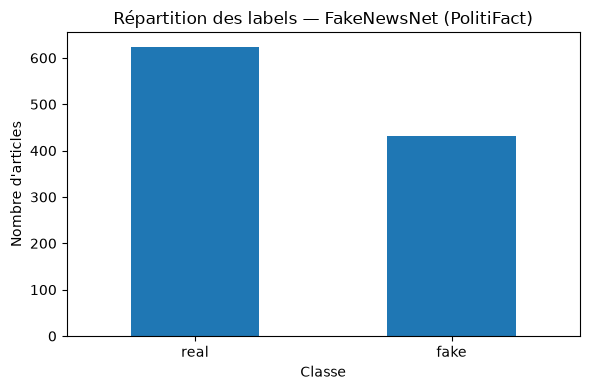

In [39]:
import matplotlib.pyplot as plt

effectifs = df_fakenewsnet["label"].value_counts()

ax = effectifs.plot(
    kind="bar",
    figsize=(6, 4)
)

ax.set_title("Répartition des labels — FakeNewsNet (PolitiFact)")
ax.set_xlabel("Classe")
ax.set_ylabel("Nombre d'articles")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

## 1.5 Qualité des données

Cette étape vise à évaluer la complétude et la cohérence du dataset.

Les contrôles portent sur :
- les valeurs manquantes ;
- les doublons ;
- les incohérences entre identifiants et labels.

Ces vérifications permettent d'identifier les éventuelles règles de nettoyage nécessaires avant l'exploitation des données.

In [40]:
# Nombre et pourcentage de valeurs manquantes
qualite_fakenewsnet = pd.DataFrame({
    "valeurs_manquantes": df_fakenewsnet.isna().sum(),
    "taux_manquant_%": (
        df_fakenewsnet.isna().mean() * 100
    ).round(2)
})

display(qualite_fakenewsnet)

,valeurs_manquantes,taux_manquant_%
id,0,0.00
news_url,61,5.78
title,0,0.00
tweet_ids,255,24.15
label,0,0.00


- Les URLs manquantes compliquent la récupération des articles d'origine.
- Les identifiants Twitter/X manquants limitent l'exploitation des données sociales.
- Les titres et les labels restent disponibles pour tous les enregistrements.

In [41]:
# Doublons exacts
doublons_exacts = df_fakenewsnet.duplicated().sum()

# Identifiants dupliqués
doublons_id = df_fakenewsnet["id"].duplicated().sum()

print("Doublons exacts :", doublons_exacts)
print("Identifiants dupliqués :", doublons_id)

Doublons exacts : 0
Identifiants dupliqués : 2


In [42]:
# Afficher toutes les lignes associées aux identifiants dupliqués
ids_dupliques = df_fakenewsnet[
    df_fakenewsnet.duplicated(subset="id", keep=False)
].sort_values("id")

display(ids_dupliques)

,id,news_url,title,tweet_ids,label
309,politifact14920,https://www.ecfr.gov/cgi-bin/text-idx?gp=&SID=...,eCFR — Code of Federal Regulations,717041881948033024\t717749291251548160\t717795...,fake
881,politifact14920,https://www.ecfr.gov/cgi-bin/text-idx?gp=&SID=...,eCFR — Code of Federal Regulations,1000393413857038337\t1000539788850548737\t1000...,real
42,politifact14940,https://www.politico.com/story/2018/01/17/full...,Full text: Jeff Flake on Trump speech transcript,922909748890128384\t922912974079188992\t922920...,fake
519,politifact14940,https://www.politico.com/story/2018/01/17/full...,Full text: Jeff Flake on Trump speech transcript,922909748890128384\t922912974079188992\t922920...,real


- Deux identifiants avec labels contradictoires

## 1.6 Multimodalité et méthodes d'extraction

Les fichiers CSV de PolitiFact contiennent des titres d'articles et des URLs, mais ne fournissent directement ni les textes intégraux ni les images.

Cette expérimentation vise à évaluer la possibilité de récupérer des contenus supplémentaires à partir des URLs disponibles.

Les contrôles portent sur :
- la disponibilité des liens ;
- l'accessibilité des pages web ;
- la présence éventuelle de métadonnées d'images ;
- les contraintes liées à une extraction complémentaire.

Les tests sont réalisés sur un échantillon limité d'articles.

In [44]:
# Nettoyage léger des URLs pour l'exploration
urls = df_fakenewsnet["news_url"].fillna("").str.strip()

# Présence d'une URL
url_presente = urls.ne("")

# Présence d'un schéma HTTP ou HTTPS
url_http = urls.str.match(r"^https?://", case=False)

# URL sans schéma explicite
url_sans_schema = url_presente & ~url_http

print("Total d'articles :", len(df_fakenewsnet))
print("URLs renseignées :", url_presente.sum())
print("URLs manquantes :", (~url_presente).sum())
print("URLs HTTP/HTTPS :", url_http.sum())
print("URLs sans schéma HTTP/HTTPS :", url_sans_schema.sum())

Total d'articles : 1056
URLs renseignées : 995
URLs manquantes : 61
URLs HTTP/HTTPS : 915
URLs sans schéma HTTP/HTTPS : 80


In [45]:
# Sélectionner cinq URLs HTTP/HTTPS distinctes
echantillon_urls = (
    df_fakenewsnet.loc[url_http, ["id", "news_url", "title"]]
    .drop_duplicates(subset="news_url")
    .head(5)
    .copy()
)

display(echantillon_urls)

,id,news_url,title
3,politifact14355,https://howafrica.com/oscar-pistorius-attempts...,Oscar Pistorius Attempts To Commit Suicide
4,politifact15371,http://washingtonsources.org/trump-votes-for-d...,Trump Votes For Death Penalty For Being Gay
6,politifact13919,http://blogs.trendolizer.com/2015/01/new-york-...,New York Man Wanted For Infecting 240 Men And ...
7,politifact14795,https://web.archive.org/web/20171027105356/htt...,Saudi Arabia to Behead 6 School Girls for Bein...
8,politifact14328,https://web.archive.org/web/20170702174006/htt...,Malia Obama Fired From Cushy Internship At Spa...


In [46]:
#Nous allons effectuer une requête HTTP sur chaque URL sélectionnéees afin de tester l'accessibilité des pages 
import requests
import time

resultats_acces = []

for _, article in echantillon_urls.iterrows():

    try:
        response = requests.get(
            article["news_url"],
            timeout=10,
            headers={
                "User-Agent": "CheckItAI-SourceResearch/0.1"
            },
            allow_redirects=True
        )

        resultats_acces.append({
            "id": article["id"],
            "statut_http": response.status_code,
            "type_contenu": response.headers.get("Content-Type"),
            "url_finale": response.url
        })

    except requests.RequestException as erreur:
        resultats_acces.append({
            "id": article["id"],
            "statut_http": None,
            "type_contenu": None,
            "url_finale": None
        })

    time.sleep(1)

df_acces = pd.DataFrame(resultats_acces)

display(df_acces)

,id,statut_http,type_contenu,url_finale
0,politifact14355,404,text/html; charset=UTF-8,https://howafrica.com/oscar-pistorius-attempts...
1,politifact15371,404,text/html,http://washingtonsources.org/trump-votes-for-d...
2,politifact13919,404,text/html; charset=iso-8859-1,http://blogs.trendolizer.com/2015/01/new-york-...
3,politifact14795,200,text/html; charset=UTF-8,https://web.archive.org/web/20171027105356/htt...
4,politifact14328,200,text/html; charset=UTF-8,https://web.archive.org/web/20170702174006/htt...


In [48]:
#Examinons une seule page HTML accessible pour déterminer si elle contient une image associée à l'article
from bs4 import BeautifulSoup

# Sélectionner une URL ayant répondu avec succès
pages_html = df_acces[
    (df_acces["statut_http"] == 200)
    & df_acces["type_contenu"].fillna("").str.contains(
        "text/html", case=False
    )
]

if pages_html.empty:
    print("Aucune page HTML accessible dans cet échantillon.")

else:
    url_test = pages_html.iloc[0]["url_finale"]

    response_html = requests.get(
        url_test,
        timeout=10,
        headers={
            "User-Agent": "CheckItAI-SourceResearch/0.1"
        }
    )

    response_html.raise_for_status()

    soup = BeautifulSoup(response_html.text, "html.parser")

    titre_html = soup.title.get_text(strip=True) if soup.title else None

    image_meta = soup.find("meta", property="og:image")

    image_url = (
        image_meta.get("content")
        if image_meta
        else None
    )

    #print("Titre HTML :", titre_html)
    print("Image Open Graph :", image_url)

Image Open Graph : None


- Sur les 1 056 enregistrements, 995 disposent d'une URL renseignée, dont 915 commencent par `http://` ou `https://`.  

- Le test d'accessibilité réalisé sur cinq URLs a retourné deux réponses HTTP 200 et trois erreurs 404. Les deux pages accessibles correspondent à des ressources archivées.  

- L'analyse HTML d'une page accessible n'a pas permis d'identifier de métadonnée `og:image`.  

Ces résultats mettent en évidence plusieurs contraintes pour une extraction multimodale : dépendance à des sites externes, liens historiques parfois indisponibles et récupération des images non garantie.


## 1.7 Synthèse et qualification de la source

### Bilan de l'exploration

| Critère                    | Résultat                                                                                                     |
| -------------------------- | ------------------------------------------------------------------------------------------------------------ |
| Source                     | FakeNewsNet — sous-ensemble PolitiFact                                                                       |
| Type                       | Dataset annoté                                                                                               |
| Format                     | CSV                                                                                                          |
| Langue                     | Principalement anglais (à confirmer sur l'ensemble des articles)                                             |
| Volume exploré             | 1 056 enregistrements                                                                                        |
| Texte disponible           | Titres et URLs des articles                                                                                  |
| Images disponibles         | Non présentes directement dans les CSV                                                                       |
| Labels                     | `fake` / `real`                                                                                              |
| Répartition des labels     | 40,91 % fake / 59,09 % real                                                                                  |
| Métadonnées                | Identifiants, URLs, références à des publications sociales                                                   |
| Qualité                    | 61 URLs manquantes, 255 valeurs `tweet_ids` manquantes, 2 identifiants associés à des labels contradictoires |
| Accessibilité des articles | 2 réponses HTTP 200 sur 5 URLs testées                                                                       |
| Méthode d'acquisition      | Téléchargement CSV ; extraction HTML complémentaire envisageable                                             |
| Droits d'utilisation       | À confirmer à partir de la documentation et des licences applicables                                         |

### Points forts

* Présence d'annotations `fake` et `real`, utiles pour étudier la désinformation.
* Structure tabulaire simple à charger et à analyser avec Python.
* Identifiants et URLs permettant de référencer les publications.
* Données adaptées à des expérimentations de nettoyage, de contrôle qualité et de déduplication.

### Limites identifiées

* Absence de textes intégraux et d'images directement dans les CSV.
* Dépendance à des sites externes pour récupérer les contenus multimodaux.
* Présence d'URLs manquantes, de liens inaccessibles et d'identifiants contradictoires.
* Récupération des images non garantie.
* Absence de justification détaillée des labels dans les fichiers explorés.
* Conditions de réutilisation des contenus externes à vérifier.

### Qualification provisoire

**Statut : source intéressante pour ses annotations, mais non retenue à ce stade comme source principale d'extraction multimodale.**

FakeNewsNet constitue une référence pertinente pour étudier des données associées à des labels de véracité. En revanche, les fichiers PolitiFact explorés nécessitent une collecte complémentaire pour obtenir des textes intégraux et des images.

Son utilisation dans le futur pipeline dépendra notamment de l'accessibilité des ressources externes, des conditions de réutilisation et de la disponibilité de données complémentaires dans le projet d'origine.

**Décision finale : à confirmer après comparaison avec les autres sources.**


### Conditions d'utilisation

FakeNewsNet est un jeu de données publié dans le cadre de travaux de recherche sur la détection de fausses informations.

Son dépôt officiel met à disposition des fichiers CSV contenant des identifiants, des titres, des URL et des références à des publications sur les réseaux sociaux.

Les auteurs précisent toutefois que le dataset complet ne peut pas être redistribué en raison des droits d'auteur des éditeurs de presse et des politiques applicables aux données issues de Twitter.


---

# 02 — Fakeddit

## 2.1 Présentation de la source

**Fakeddit** est un jeu de données multimodal issu de Reddit, conçu pour la recherche sur les contenus trompeurs et la désinformation.

Il associe notamment des publications textuelles, des références à des images et plusieurs niveaux d'annotation (`2_way_label`, `3_way_label`, `6_way_label`).

**Objectif de l'expérimentation :** évaluer la qualité des données textuelles et visuelles, comprendre les annotations et déterminer si les publications sont pertinentes pour un futur pipeline ETL consacré à la désinformation multimodale.

**Méthode d'acquisition :** téléchargement d'un fichier TSV depuis les ressources du projet.

**Points d'attention :** les publications proviennent de Reddit et peuvent concerner des sujets très variés, sans correspondre nécessairement à des articles d'actualité journalistiques.


## 2.2 Chargement des données

https://fakeddit.netlify.app/ -> https://drive.google.com/drive/folders/1jU7qgDqU1je9Y0PMKJ_f31yXRo5uWGFm   
  
    
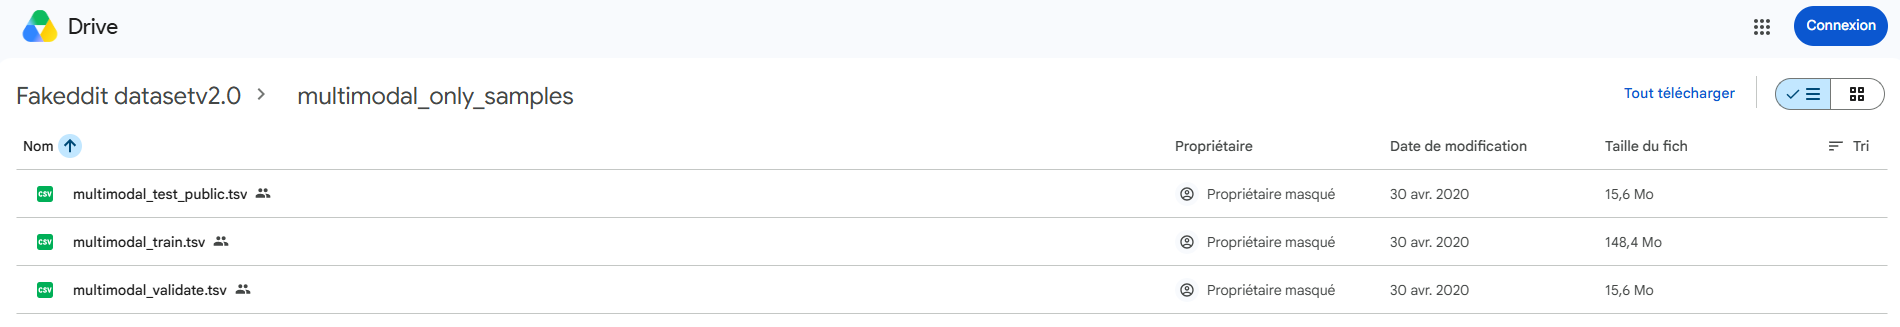


L'exploration repose sur le fichier `multimodal_validate.tsv`, issu du sous-ensemble multimodal de Fakeddit.

Ce fichier est utilisé comme échantillon de validation pour étudier la structure, les annotations et la disponibilité des images.

Les résultats obtenus décrivent ce sous-ensemble et ne doivent pas être généralisés automatiquement à l'intégralité de Fakeddit.


In [49]:
from pathlib import Path
import pandas as pd

# Chemin du fichier depuis le dossier notebooks/
fichier_fakeddit = Path("../data/raw/multimodal_validate.tsv")

# Chargement du dataset
df_fakeddit = pd.read_csv(
    fichier_fakeddit,
    sep="\t"
)

print("Dimensions :", df_fakeddit.shape)

print("\nColonnes disponibles :")
print(df_fakeddit.columns.tolist())

Dimensions : (59342, 16)

Colonnes disponibles :
['author', 'clean_title', 'created_utc', 'domain', 'hasImage', 'id', 'image_url', 'linked_submission_id', 'num_comments', 'score', 'subreddit', 'title', 'upvote_ratio', '2_way_label', '3_way_label', '6_way_label']


## 2.3 Analyse de la structure

Cette étape consiste à examiner l'organisation du dataset et à identifier les différentes catégories d'informations disponibles.

L'objectif est de distinguer les données textuelles, les références aux images, les métadonnées des publications et les annotations, afin d'évaluer le potentiel multimodal de Fakeddit.

In [51]:
# Aperçu des cinq premières publications
display(df_fakeddit.head())

# Dimensions du dataset
print("Dimensions :", df_fakeddit.shape)

# Types des colonnes
print("\nTypes de données :")
print(df_fakeddit.dtypes)

,author,clean_title,created_utc,domain,hasImage,id,image_url,linked_submission_id,num_comments,score,subreddit,title,upvote_ratio,2_way_label,3_way_label,6_way_label
0,singingdart7854,my xbox controller says hi,1.567436e+09,i.redd.it,True,cypw96,https://preview.redd.it/l0ga0tug17k31.jpg?widt...,NaN,4.0,25,mildlyinteresting,My Xbox controller says hi,0.72,1,0,0
1,mandal0re,new image from the mandalorian,1.567745e+09,i.imgur.com,True,d0bzlq,https://external-preview.redd.it/VX7bXDu9Gl8UZ...,NaN,5.0,21,photoshopbattles,PsBattle: New image from The Mandalorian,0.92,1,0,0
2,HE_WHO_DRUELS,say hello to my little friend,1.461468e+09,NaN,True,d2ezoob,http://i.imgur.com/F1Zbl3D.jpg,4g6bp9,NaN,10,psbattle_artwork,Say hello to my little friend!,NaN,0,2,4
3,eNaRDe,watch your step little one,1.408047e+09,NaN,True,cjqctpw,http://i.imgur.com/KRyMjn1.jpg,2diyh3,NaN,1,psbattle_artwork,Watch your step little one,NaN,0,2,4
4,Thebubster2001,this tree i found with a solo cup on it,1.558186e+09,i.redd.it,True,bq3yuk,https://preview.redd.it/bxp58zf01zy21.jpg?widt...,NaN,8.0,6,mildlyinteresting,This tree I found with a solo cup on it,0.62,1,0,0


Dimensions : (59342, 16)

Types de données :
author                      str
clean_title                 str
created_utc             float64
domain                      str
hasImage                   bool
id                          str
image_url                   str
linked_submission_id        str
num_comments            float64
score                     int64
subreddit                   str
title                       str
upvote_ratio            float64
2_way_label               int64
3_way_label               int64
6_way_label               int64
dtype: object


In [52]:
colonnes_multimodales = [
    "title",
    "clean_title",
    "image_url",
    "hasImage",
    "subreddit"
]

display(
    df_fakeddit[colonnes_multimodales].head(5)
)

,title,clean_title,image_url,hasImage,subreddit
0,My Xbox controller says hi,my xbox controller says hi,https://preview.redd.it/l0ga0tug17k31.jpg?widt...,True,mildlyinteresting
1,PsBattle: New image from The Mandalorian,new image from the mandalorian,https://external-preview.redd.it/VX7bXDu9Gl8UZ...,True,photoshopbattles
2,Say hello to my little friend!,say hello to my little friend,http://i.imgur.com/F1Zbl3D.jpg,True,psbattle_artwork
3,Watch your step little one,watch your step little one,http://i.imgur.com/KRyMjn1.jpg,True,psbattle_artwork
4,This tree I found with a solo cup on it,this tree i found with a solo cup on it,https://preview.redd.it/bxp58zf01zy21.jpg?widt...,True,mildlyinteresting


## 2.4 Analyse des labels

Fakeddit propose trois niveaux de classification : binaire (2 classes), intermédiaire (3 classes) et détaillé (6 classes).

Cette analyse vise à examiner la répartition des annotations, à comprendre leur signification et à évaluer leur intérêt pour un futur système d'analyse de la désinformation.

Les labels sont fournis par le dataset et ne constituent pas nécessairement des vérifications factuelles individuelles.

In [53]:
colonnes_labels = [
    "2_way_label",
    "3_way_label",
    "6_way_label"
]

for colonne in colonnes_labels:

    distribution = (
        df_fakeddit[colonne]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("label")
        .reset_index(name="effectif")
    )

    distribution["proportion_%"] = (
        distribution["effectif"]
        / len(df_fakeddit)
        * 100
    ).round(2)

    print(f"\nDistribution : {colonne}")
    display(distribution)


Distribution : 2_way_label


,label,effectif,proportion_%
0,0,36022,60.7
1,1,23320,39.3



Distribution : 3_way_label


,label,effectif,proportion_%
0,0,23320,39.3
1,1,1365,2.3
2,2,34657,58.4



Distribution : 6_way_label


,label,effectif,proportion_%
0,0,23320,39.30
1,1,3521,5.93
2,2,11277,19.00
3,3,1238,2.09
4,4,17810,30.01
5,5,2176,3.67


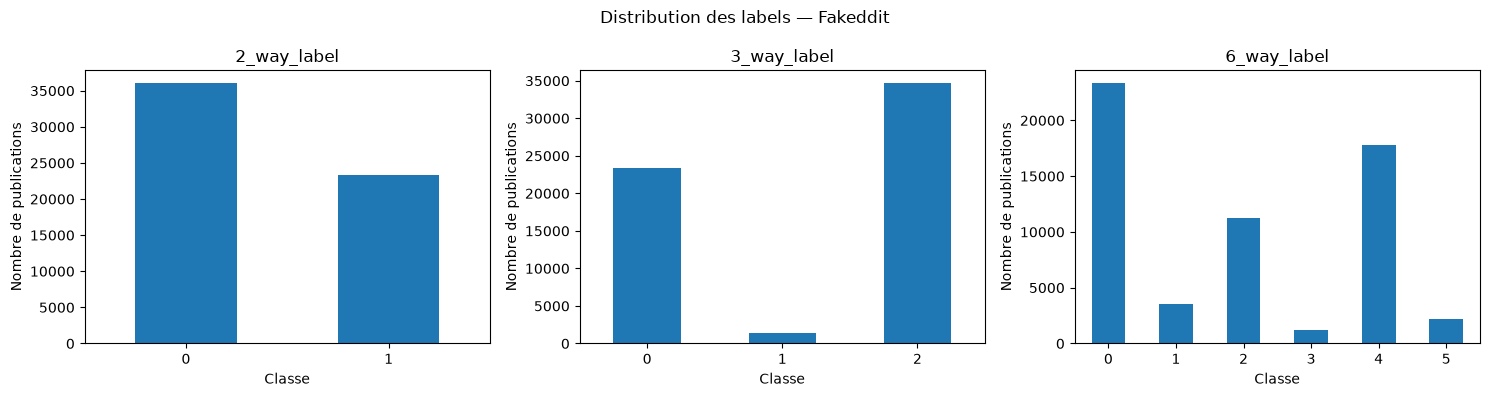

In [54]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, colonne in zip(axes, colonnes_labels):

    effectifs = (
        df_fakeddit[colonne]
        .value_counts()
        .sort_index()
    )

    effectifs.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(colonne)
    ax.set_xlabel("Classe")
    ax.set_ylabel("Nombre de publications")
    ax.tick_params(axis="x", rotation=0)

plt.suptitle("Distribution des labels — Fakeddit")
plt.tight_layout()
plt.show()

In [55]:
correspondance_labels = (
    df_fakeddit[
        ["6_way_label", "3_way_label", "2_way_label"]
    ]
    .drop_duplicates()
    .sort_values(
        ["6_way_label", "3_way_label", "2_way_label"]
    )
)

display(correspondance_labels)

,6_way_label,3_way_label,2_way_label
0,0,0,1
20,1,2,0
6,2,2,0
158,3,2,0
2,4,2,0
37,5,1,0
54,5,2,0


In [56]:
# Examiner les correspondances de la classe 5
correspondance_classe_5 = pd.crosstab(
    df_fakeddit.loc[
        df_fakeddit["6_way_label"] == 5,
        "6_way_label"
    ],
    df_fakeddit.loc[
        df_fakeddit["6_way_label"] == 5,
        "3_way_label"
    ]
)

display(correspondance_classe_5)

3_way_label,1,2
6_way_label,,
5,1365,811


### Interprétation et fiabilité des annotations

D'après l'article scientifique de Fakeddit, le dataset propose trois niveaux de classification :

* **2 classes :** distinction entre contenus considérés comme vrais ou faux.
* **3 classes :** distinction entre contenus vrais, contenus faux avec texte vrai et contenus faux avec texte faux.
* **6 classes :** classification détaillée selon différentes catégories de contenus trompeurs (`True`, `Satire/Parody`, `Misleading Content`, `Manipulated Content`, `False Connection`, `Imposter Content`).


| Catégorie               | Signification                           |
| ----------------------- | --------------------------------------- |
| **True**                | Contenu considéré comme authentique     |
| **Satire/Parody**       | Contenu humoristique ou parodique       |
| **Misleading Content**  | Contenu susceptible d'induire en erreur |
| **Manipulated Content** | Contenu modifié ou manipulé             |
| **False Connection**    | Décalage entre le texte et l'image      |
| **Imposter Content**    | Contenu qui imite ou usurpe une source  |


Ces catégories permettent d'étudier différentes formes de contenus trompeurs, au-delà d'une simple classification binaire.

**Résultats de l'exploration :**

* La classification binaire présente une répartition de 60,70 % contre 39,30 %.
* Les classifications à trois et six classes sont davantage déséquilibrées.
* La correspondance entre les niveaux d'annotation n'est pas strictement univoque : la classe `5` du niveau détaillé est associée à deux classes du niveau intermédiaire.

**Fiabilité des labels :**

Les annotations reposent principalement sur les communautés Reddit d'origine et sur une méthode de supervision distante. Elles ne correspondent donc pas systématiquement à une vérification factuelle individuelle.

L'article scientifique rapporte un coefficient de Cohen de 0,54 lors d'une évaluation humaine, révélant un accord modéré entre annotateurs.

**Conclusion provisoire :**

Fakeddit présente un intérêt pour l'étude de différentes formes de contenus trompeurs multimodaux. Cependant, ses annotations doivent être interprétées avec prudence, notamment pour les catégories ambiguës et les publications humoristiques.

*Référence : Nakamura et al. (2020), « r/Fakeddit: A New Multimodal Benchmark Dataset for Fine-grained Fake News Detection », sections 3.2 et 3.3.*


## 2.5 Qualité des données

Cette étape vise à évaluer la complétude, l'unicité et la cohérence des publications du sous-ensemble Fakeddit.

Les contrôles portent sur les valeurs manquantes, les doublons, la cohérence des informations relatives aux images et la validité des principales métadonnées.

L'objectif est d'identifier les anomalies susceptibles de nécessiter un traitement lors de la préparation des données, sans modifier le dataset à ce stade.


In [57]:
# Nombre et pourcentage de valeurs manquantes
qualite_fakeddit = pd.DataFrame({
    "valeurs_manquantes": df_fakeddit.isna().sum(),
    "taux_manquant_%": (
        df_fakeddit.isna().mean() * 100
    ).round(2)
})

display(
    qualite_fakeddit.sort_values(
        "taux_manquant_%",
        ascending=False
    )
)

,valeurs_manquantes,taux_manquant_%
linked_submission_id,41532,69.99
domain,17810,30.01
upvote_ratio,17810,30.01
num_comments,17810,30.01
author,3063,5.16
image_url,173,0.29
created_utc,0,0.00
clean_title,0,0.00
hasImage,0,0.00
id,0,0.00


In [58]:
# Doublons exacts
doublons_exacts = df_fakeddit.duplicated().sum()

# Identifiants dupliqués
doublons_id = df_fakeddit["id"].duplicated().sum()

print("Doublons exacts :", doublons_exacts)
print("Identifiants dupliqués :", doublons_id)

Doublons exacts : 0
Identifiants dupliqués : 0


In [59]:
#Vérification de la cohérence des info relatives aux images 

# Présence d'une URL d'image non vide
image_url_presente = (
    df_fakeddit["image_url"]
    .fillna("")
    .str.strip()
    .ne("")
)

# Tableau de cohérence
coherence_images = pd.crosstab(
    df_fakeddit["hasImage"],
    image_url_presente,
    rownames=["hasImage"],
    colnames=["image_url présente"]
)

display(coherence_images)

image_url présente,False,True
hasImage,,
True,173,59169


In [60]:
#Validité des métadonnées
# Conversion des timestamps Unix en dates
dates_publication = pd.to_datetime(
    df_fakeddit["created_utc"],
    unit="s",
    utc=True,
    errors="coerce"
)

print("Dates invalides :", dates_publication.isna().sum())

if dates_publication.notna().any():
    print("Date minimale :", dates_publication.min())
    print("Date maximale :", dates_publication.max())

# Contrôles numériques
print(
    "\nNombre de commentaires négatif :",
    (df_fakeddit["num_comments"] < 0).sum()
)

print(
    "Ratios de votes hors [0, 1] :",
    (
        (df_fakeddit["upvote_ratio"] < 0)
        | (df_fakeddit["upvote_ratio"] > 1)
    ).sum()
)

Dates invalides : 0
Date minimale : 2008-07-03 12:12:23+00:00
Date maximale : 2019-10-23 07:37:54+00:00

Nombre de commentaires négatif : 0
Ratios de votes hors [0, 1] : 0


### Observation

- L'analyse du sous-ensemble Fakeddit révèle une bonne complétude des champs essentiels : les titres, les identifiants et les trois niveaux d'annotation sont renseignés pour l'ensemble des 59 342 publications.

- Les URLs d'images sont disponibles pour **99,71 % des enregistrements**. Toutefois, 173 publications possèdent un indicateur `hasImage = True` sans URL d'image renseignée.

- Aucun doublon exact ni identifiant dupliqué n'a été détecté.

- Certaines métadonnées complémentaires présentent des taux de valeurs manquantes importants, notamment `linked_submission_id` (69,99 %), `domain`, `num_comments` et `upvote_ratio` (30,01 % chacun). Ces absences ne constituent pas nécessairement des anomalies et devront être interprétées selon la structure du dataset. *(Piste d'investigation: voir classe 4 de `6_way_label`)*   

- Les contrôles de validité n'ont révélé aucune date invalide, aucun nombre de commentaires négatif et aucun ratio de votes hors de l'intervalle [0, 1].

- Les publications couvrent une période allant de **2008 à 2019**, ce qui caractérise Fakeddit comme une source de données historiques.  

**Conclusion provisoire :** le sous-ensemble présente une bonne qualité structurelle pour l'exploitation de données textuelles et d'annotations. La disponibilité effective des images reste toutefois à vérifier, de même que la pertinence des publications pour notre cas d'usage.


## 2.6 Multimodalité et pertinence métier

Cette étape vise à évaluer l'exploitabilité des données textuelles et visuelles de Fakeddit, ainsi que leur adéquation avec les besoins du projet CheckIt.AI.

Les expérimentations portent sur :

* l'accessibilité des images référencées ;
* la validité technique des fichiers récupérés ;
* la nature des publications et des communautés Reddit ;
* la pertinence des contenus pour un futur pipeline d'actualités multimodales.

Les tests de téléchargement sont limités à un petit échantillon afin de conserver une démarche exploratoire.


Testons l'accessibilité des images :

In [61]:
# Sélectionner les publications possédant une URL d'image
publications_images = df_fakeddit[
    df_fakeddit["image_url"].notna()
    & df_fakeddit["image_url"].str.strip().ne("")
]

# Échantillon reproductible de 10 publications
echantillon_images = publications_images.sample(
    n=10,
    random_state=42
)

display(
    echantillon_images[
        ["id", "title", "subreddit", "image_url"]
    ]
)

,id,title,subreddit,image_url
3109,b1zhm5,This happy footprint in the snow,pareidolia,https://preview.redd.it/5curj3nhskm21.jpg?widt...
21752,cxwcxhw,Unhealthy Fat Kitty Vader,psbattle_artwork,http://i.imgur.com/utlciFy.jpg
4558,4yyjbv,Exhibitionist carrots,pareidolia,https://external-preview.redd.it/9slkO-pV7N0fO...
8701,ccahalp,Other Discussions,psbattle_artwork,http://i.imgur.com/sqTJih1%2ejpg
36544,d0ailn,The bug bite on my leg looks like Wilson.,mildlyinteresting,https://preview.redd.it/jfs132izvvk31.jpg?widt...
41963,d1joetp,Boom,psbattle_artwork,http://i.imgur.com/dwzlg2i.jpg
27612,cn3mcxz,Lord Starfish needs YOU!,psbattle_artwork,http://i.imgur.com/IsxLYYp.jpg
4259,7bleg4,Flat-faced kitty with a Mohawk,misleadingthumbnails,https://preview.redd.it/vwm1fz7nvmwz.jpg?width...
47831,7sh07p,Retraux Robert — The Biggest Rip Off Of Them A...,fakealbumcovers,https://external-preview.redd.it/wb4udI2VrQ25C...
9507,b0ibs0,Venezuelan man takes out the equivalent of $5 ...,fakehistoryporn,https://preview.redd.it/7p7yj3ysptl21.jpg?widt...


In [62]:
import requests
import time

from io import BytesIO
from PIL import Image, UnidentifiedImageError

resultats_images = []

for _, article in echantillon_images.iterrows():

    resultat = {
        "id": article["id"],
        "statut_http": None,
        "image_valide": False,
        "format": None,
        "erreur": None
    }

    try:
        response = requests.get(
            article["image_url"],
            timeout=15,
            headers={
                "User-Agent": "CheckItAI-SourceResearch/0.1"
            }
        )

        resultat["statut_http"] = response.status_code

        response.raise_for_status()

        # Vérifier que le contenu est une image valide
        with Image.open(BytesIO(response.content)) as image:
            image.verify()
            resultat["format"] = image.format

        resultat["image_valide"] = True

    except (
        requests.RequestException,
        UnidentifiedImageError,
        OSError
    ) as erreur:

        resultat["erreur"] = str(erreur)[:120]

    resultats_images.append(resultat)

    # Petite pause entre les requêtes
    time.sleep(1)

df_resultats_images = pd.DataFrame(resultats_images)

display(df_resultats_images)

,id,statut_http,image_valide,format,erreur
0,b1zhm5,404,False,NaN,404 Client Error: Not Found for url: https://p...
1,cxwcxhw,200,True,JPEG,NaN
2,4yyjbv,200,True,JPEG,NaN
3,ccahalp,200,True,JPEG,NaN
4,d0ailn,200,True,JPEG,NaN
5,d1joetp,200,True,PNG,NaN
6,cn3mcxz,200,True,JPEG,NaN
7,7bleg4,404,False,NaN,404 Client Error: Not Found for url: https://p...
8,7sh07p,200,True,JPEG,NaN
9,b0ibs0,200,True,JPEG,NaN


Analysons les communautés Reddit (pertinence métier) :

In [63]:
# Les 10 communautés les plus représentées
top_subreddits = (
    df_fakeddit["subreddit"]
    .value_counts()
    .head(10)
    .rename_axis("subreddit")
    .reset_index(name="nombre_publications")
)

top_subreddits["proportion_%"] = (
    top_subreddits["nombre_publications"]
    / len(df_fakeddit)
    * 100
).round(2)

display(top_subreddits)

,subreddit,nombre_publications,proportion_%
0,psbattle_artwork,17810,30.01
1,mildlyinteresting,8988,15.15
2,photoshopbattles,5935,10.00
3,pareidolia,4980,8.39
4,fakehistoryporn,3770,6.35
5,nottheonion,3339,5.63
6,upliftingnews,2505,4.22
7,fakealbumcovers,2230,3.76
8,misleadingthumbnails,1677,2.83
9,propagandaposters,1365,2.30


In [64]:
# Sélectionner une publication par communauté parmi les 10 principales
communautes = top_subreddits["subreddit"]

exemples_publications = (
    df_fakeddit[
        df_fakeddit["subreddit"].isin(communautes)
    ]
    .groupby("subreddit", group_keys=False)
    .sample(n=1, random_state=42)
)

display(
    exemples_publications[
        [
            "subreddit",
            "title",
            "2_way_label",
            "3_way_label",
            "6_way_label"
        ]
    ]
)

,subreddit,title,2_way_label,3_way_label,6_way_label
1650,fakealbumcovers,loophole - Self-titled,0,2,1
12550,fakehistoryporn,Johnny Depp reveals that he's actually a femal...,0,2,2
3766,mildlyinteresting,"In the city I'm staying at at the moment, they...",1,0,0
1134,misleadingthumbnails,Black swan,0,2,2
46324,nottheonion,Indonesia apologizes for posters saying sneezi...,1,0,0
53847,pareidolia,Onion angry faces,0,2,2
21958,photoshopbattles,PsBattle: Pitbull wearing sunglasses with a dr...,1,0,0
3773,propagandaposters,"""Dick-tator Nixon"" 1973.",0,1,5
10147,psbattle_artwork,Bunny season,0,2,4
25517,upliftingnews,Aspiring author opens own publishing house aft...,1,0,0


### Observation

**Accessibilité des images :**

Sur dix URLs testées, huit ont permis de récupérer des images techniquement valides (JPEG ou PNG), tandis que deux ont retourné une erreur HTTP 404.

Ce résultat confirme la possibilité d'extraire directement des images à partir des URLs fournies par Fakeddit. Toutefois, la disponibilité des ressources externes n'est pas garantie et les résultats de cet échantillon ne peuvent pas être généralisés à l'ensemble du dataset.

**Nature des publications :**

L'analyse des communautés Reddit montre une diversité de publications : contenus humoristiques, créations visuelles, images manipulées, publications informatives et contenus proches de l'actualité.


**Pertinence pour le projet :**

Fakeddit répond au besoin de disposer de publications associant texte et image. La diversité des contenus constitue un intérêt pour l'étude de différentes formes de désinformation, notamment les manipulations visuelles et les décalages entre texte et image.

Les principales limites concernent la fiabilité des annotations, la disponibilité des images externes et le caractère historique du dataset.

**Conclusion provisoire :**

Fakeddit constitue une source pertinente pour préparer des données multimodales destinées à un futur système d'analyse de la désinformation.

Son utilisation comme source principale devra néanmoins être comparée à celle des API et des flux de publications, notamment pour évaluer les possibilités d'automatisation, d'actualisation et les droits de réutilisation.


Vérification de la disponibilité des images : 

In [65]:
exemple = df_fakeddit[
    df_fakeddit["image_url"].notna()
].iloc[0]

print("Identifiant :", exemple["id"])
print("Titre :", exemple["title"])
print("URL image :", exemple["image_url"])
print("Label binaire :", exemple["2_way_label"])

Identifiant : cypw96
Titre : My Xbox controller says hi
URL image : https://preview.redd.it/l0ga0tug17k31.jpg?width=320&crop=smart&auto=webp&s=ef3396b88eba2a0ed976b0d6b6ee9ea29733d32d
Label binaire : 1


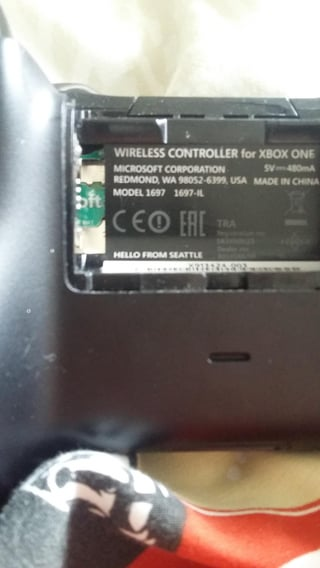

In [66]:
import requests
from io import BytesIO
from PIL import Image
from IPython.display import display

url_image = exemple["image_url"]

response = requests.get(
    url_image,
    timeout=15,
    headers={"User-Agent": "Mozilla/5.0"}
)

response.raise_for_status()

image = Image.open(BytesIO(response.content))

display(image)

## 2.7 Synthèse et qualification de la source

### Bilan de l'exploration

| Critère                  | Résultat                                                            |
| ------------------------ | ------------------------------------------------------------------- |
| Source                   | Fakeddit                                                            |
| Type                     | Dataset multimodal annoté                                           |
| Format                   | TSV                                                                 |
| Langue                   | Anglais principalement                                              |
| Volume exploré           | 59 342 publications (sous-ensemble de validation)                   |
| Texte disponible         | Titres originaux et nettoyés                                        |
| Images disponibles       | URLs d'images associées aux publications                            |
| Labels                   | Classifications à 2, 3 et 6 classes                                 |
| Qualité des annotations  | Supervision distante ; fiabilité à interpréter avec prudence        |
| Complétude               | 100 % des titres et labels ; 99,71 % des URLs d'images              |
| Doublons                 | Aucun doublon exact ni identifiant dupliqué détecté                 |
| Accessibilité des images | 8 images valides sur 10 URLs testées                                |
| Période couverte         | 2008–2019                                                           |
| Provenance               | Publications Reddit et communautés associées                        |
| Méthode d'acquisition    | Téléchargement TSV, puis récupération HTTP des images               |
| Automatisation           | Possible pour l'import des fichiers et le téléchargement des images |
| Actualisation            | Dataset historique ; collecte continue non démontrée                |
| Droits d'utilisation     | À vérifier pour le dataset et les images d'origine                  |

### Points forts

* Association directe entre titres et références d'images.
* Plusieurs niveaux d'annotation pour étudier différentes formes de contenus trompeurs.
* Bonne complétude des champs essentiels.
* Métadonnées permettant de retracer les communautés d'origine.
* Structure adaptée à des traitements automatisés de validation et de préparation multimodale.

### Limites identifiées

* Certaines images ne sont plus accessibles.
* Les annotations reposent principalement sur une méthode de supervision distante et ne constituent pas des vérifications factuelles individuelles.
* Les publications sont historiques et ne permettent pas, à elles seules, de mettre en place une collecte continue d'actualités.
* Les textes disponibles sont principalement des titres, et non des articles complets.
* Les conditions de conservation et de réutilisation des images externes doivent être vérifiées.

### Qualification provisoire

**Statut : source candidate pertinente pour un pipeline ETL multimodal.**

Fakeddit présente de bonnes caractéristiques pour l'acquisition et la préparation de publications associant texte et image. Ses annotations constituent également un intérêt pour de futures expérimentations sur la désinformation.

Cependant, son caractère historique et la dépendance à des images hébergées sur des plateformes externes limitent les possibilités d'actualisation.

**Décision finale : à confirmer après comparaison avec les autres sources, notamment les API, les flux RSS...**


### Conditions d'utilisation

Fakeddit est un jeu de données multimodal développé pour la recherche scientifique sur la détection de fausses informations.

Les auteurs mettent à disposition des données textuelles, des métadonnées, des labels de classification et des ressources permettant de récupérer les images associées aux publications.

Cette mise à disposition facilite les expérimentations scientifiques et l'évaluation de modèles multimodaux. Elle ne garantit toutefois pas que l'ensemble des images provenant de Reddit ou de sites tiers puisse être librement redistribué ou exploité commercialement.


---

# 03 — NewsData.io

## 3.1 Présentation de la source

**NewsData.io** est un service proposant une API REST permettant de rechercher et de récupérer des publications d'actualité provenant de différentes sources d'information.

L'API retourne des données structurées au format JSON, comprenant notamment des titres, des descriptions, des URLs d'articles, des références d'images et des métadonnées de publication.

**Objectif de l'expérimentation :** évaluer la capacité de l'API à fournir des publications textuelles et visuelles exploitables dans un pipeline ETL automatisé.

**Méthode d'acquisition :** requêtes HTTP vers une API REST, avec authentification par clé API.

**Points d'attention :** quotas d'utilisation, pagination, disponibilité des descriptions et des images, restrictions d'accès au contenu intégral et absence éventuelle de labels de véracité.

L'exploration portera également sur la possibilité de collecter des actualités françaises et généralistes.


## 3.2 Acquisition des données

Cette expérimentation consiste à interroger l'API REST de NewsData.io afin de récupérer un échantillon de publications d'actualité.

La requête privilégie les publications en français, sans imposer de catégorie thématique.

L'objectif est de vérifier le fonctionnement de l'authentification, la structure de la réponse JSON et les possibilités de pagination.

Les données récupérées seront utilisées pour les analyses suivantes, sans multiplier inutilement les appels à l'API.


In [67]:
import os
import requests

from pathlib import Path
from dotenv import load_dotenv

# Charger les variables d'environnement
load_dotenv(dotenv_path=Path("../.env"))

api_key = os.getenv("NEWSDATA_API_KEY")

if not api_key:
    raise ValueError("Clé API NewsData.io introuvable dans le fichier .env")

# Endpoint de l'API
url_newsdata = "https://newsdata.io/api/1/latest"

# Paramètres de la requête
params_newsdata = {
    "apikey": api_key,
    "language": "fr"
}

In [68]:
response_newsdata = requests.get(
    url_newsdata,
    params=params_newsdata,
    timeout=20
)

print("Code HTTP :", response_newsdata.status_code)

response_newsdata.raise_for_status()

data_newsdata = response_newsdata.json()

print("Statut API :", data_newsdata.get("status"))
print("Nombre total de résultats :", data_newsdata.get("totalResults"))
print("Articles reçus :", len(data_newsdata.get("results", [])))
print("Pagination disponible :", bool(data_newsdata.get("nextPage")))

Code HTTP : 200
Statut API : success
Nombre total de résultats : 23093
Articles reçus : 10
Pagination disponible : True


True confirme que NewsData.io nous fournit un jeton permettant de demander la page suivante

## 3.3 Analyse de la structure

Cette étape consiste à examiner les champs retournés par l'API NewsData.io et à identifier les différentes catégories d'informations disponibles.

L'objectif est de distinguer les données textuelles, les références aux images, les métadonnées de publication et les informations relatives à la provenance des articles.

L'analyse repose sur les dix articles récupérés lors de la requête précédente, sans effectuer de nouvel appel à l'API.


In [69]:
# Conversion des articles JSON en DataFrame
df_newsdata = pd.DataFrame(data_newsdata["results"])

# Dimensions
print("Dimensions :", df_newsdata.shape)

# Colonnes disponibles
print("\nColonnes disponibles :")
print(df_newsdata.columns.tolist())

Dimensions : (10, 28)

Colonnes disponibles :
['article_id', 'link', 'title', 'description', 'content', 'keywords', 'creator', 'language', 'country', 'category', 'datatype', 'pubDate', 'pubDateTZ', 'fetched_at', 'image_url', 'video_url', 'source_id', 'source_name', 'source_priority', 'source_url', 'source_icon', 'sentiment', 'sentiment_stats', 'ai_tag', 'ai_region', 'ai_org', 'ai_summary', 'duplicate']


In [72]:
print(df_newsdata.columns)

Index(['article_id', 'link', 'title', 'description', 'content', 'keywords',
       'creator', 'language', 'country', 'category', 'datatype', 'pubDate',
       'pubDateTZ', 'fetched_at', 'image_url', 'video_url', 'source_id',
       'source_name', 'source_priority', 'source_url', 'source_icon',
       'sentiment', 'sentiment_stats', 'ai_tag', 'ai_region', 'ai_org',
       'ai_summary', 'duplicate'],
      dtype='str')


In [70]:
# Sélection des principales informations
colonnes_apercu = [
    "article_id",
    "title",
    "description",
    "image_url",
    "source_name",
    "pubDate"
]

display(df_newsdata[colonnes_apercu].head(5))

print("\nTypes de données :")
print(df_newsdata[colonnes_apercu].dtypes)

,article_id,title,description,image_url,source_name,pubDate
0,0976a82700918e07e2e8d3331154e2b3,Une mère et sa fille victimes d’un désaxé sexu...,Une fête des voisins se termine en correctionn...,https://www.lavenir.net/resizer/v2/ULF5MPY62FC...,Lavenir Net,2026-10-24 03:55:00
1,5a984e0363f8b86ff9aa25871c160ba6,De retour à l’ULiège un mois après son violent...,Un mois après avoir été violemment entarté en ...,https://spgeng.rosselcdn.net/sites/default/fil...,Sudinfo,2026-10-24 03:55:00
2,0f0166fddb2608c86be2f1f1064e2bce,Meung-sur-Loire : réunion sur les travaux de v...,NaN,https://www.larep.fr/photoSRC/VVZTJ19dUTgIDAVO...,Larep Fr,2026-10-24 03:55:00
3,5d1ed9f0227eb621c788ab253e8df296,Montauban. La fondation Opteo inaugure sa Mais...,"Reconnue d’utilité publique, la fondation née ...",https://images.ladepeche.fr/api/v1/images/view...,Ladepeche,2026-10-24 03:54:07
4,1acb2c0459036853adb51db0a2635793,Rodez et Decazeville De nouvelles interpellati...,Lors de la manifestation du 17 octobre à Rodez...,NaN,Ladepeche,2026-10-24 03:54:07



Types de données :
article_id     str
title          str
description    str
image_url      str
source_name    str
pubDate        str
dtype: object


In [71]:
# Examiner le contenu textuel retourné pour trois articles
for index, article in df_newsdata.head(3).iterrows():

    print(f"\nArticle {index + 1}")
    print("Titre :", article["title"])
    print("Description :", article["description"])
    print("Contenu :", article["content"])
    print("-" * 60)


Article 1
Titre : Une mère et sa fille victimes d’un désaxé sexuel lors d’une fête à Chastre
Description : Une fête des voisins se termine en correctionnelle pour trois participants: une mère et sa fille, victimes d’un homme condamné à 18 mois de probation. ...
Contenu : ONLY AVAILABLE IN PAID PLANS
------------------------------------------------------------

Article 2
Titre : De retour à l’ULiège un mois après son violent entartage, Damien Ernst décrit ses agresseurs : « Des jeunes qui se prennent pour Che Guevara ! » (vidéo)
Description : Un mois après avoir été violemment entarté en plein cours à l’ULiège, Damien Ernst a repris ses activités. Le professeur, qui affirme être rétabli, revient sur les conséquences de son agression et livre son analyse du profil de ses agresseurs.
Contenu : ONLY AVAILABLE IN PAID PLANS
------------------------------------------------------------

Article 3
Titre : Meung-sur-Loire : réunion sur les travaux de voirie à la Nivelle et impacts sur le quart

### Observation

La réponse de l'API NewsData.io contient **10 articles et 28 champs**, organisés autour des contenus textuels, des références d'images, des métadonnées de publication et des informations de provenance.

Les champs `article_id`, `link`, `source_name` et `pubDate` permettent d'envisager l'identification et la traçabilité des publications dans un futur pipeline ETL.

Les données textuelles comprennent les titres et les descriptions, tandis que les images sont référencées par le champ `image_url`. Certaines descriptions et URLs d'images sont toutefois absentes dans l'échantillon observé.

**Restriction identifiée :** le champ `content` contient la valeur `ONLY AVAILABLE IN PAID PLANS` pour les trois articles examinés. Le texte intégral n'est donc pas directement accessible dans ces réponses avec le forfait utilisé.

**Conclusion provisoire :**

NewsData.io fournit une structure adaptée à l'acquisition automatisée de publications d'actualité en français, avec des métadonnées utiles à leur traçabilité.

Son exploitation multimodale dépendra cependant de la disponibilité effective des descriptions et des images. L'absence de contenu intégral dans le forfait testé constitue également une limitation à prendre en compte.


**Note :**   
Contrairement à FakeNewsNet et Fakeddit, NewsData.io permet d'interroger une API pour obtenir de nouvelles publications.  

Cela constitue un avantage potentiel pour un pipeline automatisé et régulièrement exécuté.  

Mais il faudra tenir compte :  

- Des quotas d'appels.
- De la pagination.
- Des restrictions du forfait.
- Des articles potentiellement dupliqués.
- Des images indisponibles.
- Des conditions de réutilisation des contenus.

## 3.4 Analyse des labels et des annotations

Cette étape vise à déterminer si les publications récupérées via NewsData.io disposent d'annotations relatives à leur véracité.

L'analyse porte également sur les champs de classification et les métadonnées complémentaires fournis par l'API.

L'objectif est de distinguer les informations descriptives des véritables labels de fact-checking, afin d'évaluer leur intérêt pour le projet CheckIt.AI.


In [73]:
# Champs à examiner
colonnes_annotations = [
    "category",
    "sentiment",
    "ai_tag",
    "duplicate"
]

# Aperçu des annotations disponibles
display(
    df_newsdata[colonnes_annotations].head(10)
)

,category,sentiment,ai_tag,duplicate
0,[top],negative,None,False
1,"[top, politics]",negative,[politics],False
2,"[top, politics]",neutral,[politics],False
3,[health],positive,[nonprofit organizations],False
4,[crime],neutral,[accidents],False
5,[sports],positive,[motorsports],False
6,[education],positive,"[human rights, nonprofit organizations]",False
7,[health],positive,[nonprofit organizations],False
8,[entertainment],positive,[nonprofit organizations],False
9,[education],positive,[sports],False


In [74]:
# Complétude des champs d'annotation
disponibilite_annotations = pd.DataFrame({
    "valeurs_renseignees": (
        df_newsdata[colonnes_annotations].notna().sum()
    ),
    "valeurs_manquantes": (
        df_newsdata[colonnes_annotations].isna().sum()
    )
})

display(disponibilite_annotations)

,valeurs_renseignees,valeurs_manquantes
category,10,0
sentiment,10,0
ai_tag,9,1
duplicate,10,0


In [75]:
# Rechercher d'éventuels champs associés à la véracité
mots_cles_veracite = [
    "fake",
    "real",
    "truth",
    "fact_check",
    "veracity"
]

colonnes_veracite = [
    colonne
    for colonne in df_newsdata.columns
    if any(
        mot in colonne.lower()
        for mot in mots_cles_veracite
    )
]

print("Colonnes potentiellement liées à la véracité :")
print(colonnes_veracite)

Colonnes potentiellement liées à la véracité :
[]


### Informations potentiellement utiles à la vérification

En l'absence de labels explicites de véracité, certaines métadonnées peuvent néanmoins contribuer à une analyse ultérieure des publications.

Les titres et descriptions permettent d'identifier les affirmations à examiner. Les informations de provenance, d'auteur et de publication facilitent leur contextualisation et leur traçabilité.

Les mots-clés et les catégories peuvent également aider à rapprocher des publications portant sur des sujets similaires.

Cette expérimentation vise à examiner la disponibilité et le contenu de ces informations, sans les interpréter comme des preuves de véracité.


In [76]:
colonnes_verification = [
    "title",
    "description",
    "keywords",
    "creator",
    "source_name",
    "source_url",
    "pubDate",
    "category"
]

# Examiner trois articles
display(
    df_newsdata[colonnes_verification].head(3).T
)

,0,1,2
title,Une mère et sa fille victimes d’un désaxé sexu...,De retour à l’ULiège un mois après son violent...,Meung-sur-Loire : réunion sur les travaux de v...
description,Une fête des voisins se termine en correctionn...,Un mois après avoir été violemment entarté en ...,NaN
keywords,[brabant wallon],[liège actu],[meung-sur-loire]
creator,[jean vandendries],[quentin cools],None
source_name,Lavenir Net,Sudinfo,Larep Fr
source_url,https://www.lavenir.net,https://www.sudinfo.be,https://www.larep.fr
pubDate,2026-10-24 03:55:00,2026-10-24 03:55:00,2026-10-24 03:55:00
category,[top],"[top, politics]","[top, politics]"


In [77]:
disponibilite_verification = pd.DataFrame({
    "valeurs_renseignees": (
        df_newsdata[colonnes_verification].notna().sum()
    ),
    "taux_renseigne_%": (
        df_newsdata[colonnes_verification].notna().mean() * 100
    ).round(2)
})

display(disponibilite_verification)

,valeurs_renseignees,taux_renseigne_%
title,10,100.0
description,9,90.0
keywords,10,100.0
creator,9,90.0
source_name,10,100.0
source_url,10,100.0
pubDate,10,100.0
category,10,100.0


### Observation

**Annotations disponibles :**

Les dix articles explorés disposent de catégories thématiques, d'informations de sentiment et d'un indicateur de duplication. Le champ `ai_tag` est renseigné pour neuf articles.

Ces métadonnées décrivent certaines caractéristiques des publications, mais ne constituent pas des annotations de véracité.

**Informations utiles à la vérification :**

Les champs `title`, `keywords`, `source_name`, `source_url`, `pubDate` et `category` sont renseignés pour les dix articles. Les champs `description` et `creator` sont disponibles pour neuf articles.

Ces informations facilitent l'identification, la contextualisation et la traçabilité des publications. Elles pourraient également contribuer à un futur processus de rapprochement avec des données de fact-checking.

**Qualité des labels de véracité :**

Aucun label explicite `fake` / `real` n'a été identifié dans les données récupérées.

Les informations disponibles ne permettent donc pas de déterminer directement si un article contient une affirmation vraie, fausse ou trompeuse.

**Conclusion provisoire :**

NewsData.io constitue une source intéressante pour l'acquisition de publications d'actualité et de métadonnées exploitables dans un pipeline multimodal.

En revanche, les données récupérées ne sont pas directement adaptées à l'entraînement supervisé d'un détecteur de fake news, faute d'annotations de véracité.

Une utilisation à cette fin nécessiterait une étape complémentaire de vérification et d'annotation, éventuellement à partir de sources spécialisées en fact-checking.

La faisabilité de cette approche devra être étudiée avant de retenir NewsData.io comme source principale.


## 3.5 Analyse de la qualité des données

Cette étape vise à évaluer la qualité des publications récupérées via l'API NewsData.io.

Les contrôles portent sur la complétude des champs, la présence de doublons, la cohérence des dates et l'exploitabilité des données textuelles.

Une attention particulière est accordée aux restrictions d'accès au contenu intégral, afin de distinguer les informations réellement disponibles des champs présents uniquement dans la structure JSON.

L'analyse repose sur les dix articles précédemment récupérés, sans nouvel appel à l'API.


In [78]:
# Colonnes essentielles pour le pipeline multimodal
colonnes_qualite = [
    "article_id",
    "link",
    "title",
    "description",
    "content",
    "image_url",
    "source_name",
    "source_url",
    "pubDate",
    "language"
]

qualite_newsdata = pd.DataFrame({
    "valeurs_manquantes": (
        df_newsdata[colonnes_qualite].isna().sum()
    ),
    "taux_manquant_%": (
        df_newsdata[colonnes_qualite].isna().mean() * 100
    ).round(2)
})

display(
    qualite_newsdata.sort_values(
        "taux_manquant_%",
        ascending=False
    )
)

,valeurs_manquantes,taux_manquant_%
image_url,1,10.0
description,1,10.0
link,0,0.0
article_id,0,0.0
title,0,0.0
content,0,0.0
source_name,0,0.0
source_url,0,0.0
pubDate,0,0.0
language,0,0.0


In [79]:
# Contrôle des doublons
print(
    "Doublons exacts :",
    df_newsdata.astype(str).duplicated().sum()
)

print(
    "Identifiants dupliqués :",
    df_newsdata["article_id"].duplicated().sum()
)

print(
    "URLs d'articles dupliquées :",
    df_newsdata["link"].dropna().duplicated().sum()
)

# Indicateur fourni par l'API
print("\nIndicateur duplicate :")
print(df_newsdata["duplicate"].value_counts(dropna=False))

Doublons exacts : 0
Identifiants dupliqués : 0
URLs d'articles dupliquées : 0

Indicateur duplicate :
duplicate
False    10
Name: count, dtype: int64


In [80]:
# Conversion temporaire pour l'analyse
dates_newsdata = pd.to_datetime(
    df_newsdata["pubDate"],
    errors="coerce",
    utc=True
)

print(
    "Dates invalides :",
    dates_newsdata.isna().sum()
)

print(
    "Date minimale :",
    dates_newsdata.min()
)

print(
    "Date maximale :",
    dates_newsdata.max()
)

Dates invalides : 0
Date minimale : 2026-10-24 03:53:08+00:00
Date maximale : 2026-10-24 03:55:00+00:00


In [81]:
# Vérifier la présence de textes non vides
for colonne in ["title", "description"]:

    texte = df_newsdata[colonne].fillna("").str.strip()

    print(f"\n{colonne}")
    print("Textes exploitables :", texte.ne("").sum())
    print("Textes absents ou vides :", texte.eq("").sum())

    longueurs = texte[texte.ne("")].str.len()

    if not longueurs.empty:
        print(
            "Longueur médiane :",
            longueurs.median(),
            "caractères"
        )


title
Textes exploitables : 10
Textes absents ou vides : 0
Longueur médiane : 76.0 caractères

description
Textes exploitables : 9
Textes absents ou vides : 1
Longueur médiane : 213.0 caractères


In [82]:
# Examiner les restrictions d'accès au contenu intégral
contenus = (
    df_newsdata["content"]
    .fillna("")
    .astype(str)
    .str.strip()
)

contenu_restreint = contenus.str.contains(
    "ONLY AVAILABLE IN PAID PLANS",
    case=False,
    regex=False
)

contenu_absent = contenus.eq("")

contenu_exploitable = (
    ~contenu_restreint
    & ~contenu_absent
)

print(
    "Contenus restreints :",
    contenu_restreint.sum()
)

print(
    "Contenus absents ou vides :",
    contenu_absent.sum()
)

print(
    "Contenus potentiellement exploitables :",
    contenu_exploitable.sum()
)

Contenus restreints : 10
Contenus absents ou vides : 0
Contenus potentiellement exploitables : 0


## 3.6 Analyse des modalités et de leur accessibilité

Cette étape vise à évaluer les possibilités d'acquisition multimodale offertes par NewsData.io.

Les modalités examinées sont :

* **Texte :** titres et descriptions disponibles, contenu intégral soumis aux restrictions du forfait.
* **Image :** URLs fournies par l'API, dont l'accessibilité et la validité doivent être vérifiées.
* **Vidéo :** références éventuellement disponibles dans le champ `video_url`.

L'objectif est de distinguer la présence de références multimédias dans la réponse JSON de la possibilité de récupérer effectivement les ressources correspondantes.

Les tests seront limités aux dix articles déjà collectés.


In [84]:
# Champs multimédias
colonnes_multimedia = [
    "image_url",
    "video_url"
]

# Présence de références non vides
disponibilite_multimedia = pd.DataFrame({
    "references_presentes": [
        df_newsdata[colonne]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        .sum()
        for colonne in colonnes_multimedia
    ],
    "references_absentes": [
        df_newsdata[colonne]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
        for colonne in colonnes_multimedia
    ]
}, index=colonnes_multimedia)

display(disponibilite_multimedia)

,references_presentes,references_absentes
image_url,9,1
video_url,1,9


In [86]:
# Examiner les références vidéo
videos_disponibles = df_newsdata.loc[
    df_newsdata["video_url"].notna(),
    ["article_id", "title", "video_url"]
]

display(videos_disponibles)

,article_id,title,video_url
1,5a984e0363f8b86ff9aa25871c160ba6,De retour à l’ULiège un mois après son violent...,https://www.sudinfo.be/id1214852/article/2026-...


In [87]:
import requests

from io import BytesIO
from PIL import Image, UnidentifiedImageError

resultats_images_newsdata = []

# Articles possédant une URL d'image
articles_avec_images = df_newsdata[
    df_newsdata["image_url"].notna()
    & df_newsdata["image_url"].str.strip().ne("")
]

for _, article in articles_avec_images.iterrows():

    resultat = {
        "article_id": article["article_id"],
        "statut_http": None,
        "image_valide": False,
        "format": None,
        "erreur": None
    }

    try:
        response_image = requests.get(
            article["image_url"],
            timeout=15,
            headers={
                "User-Agent": "CheckItAI-SourceResearch/0.1"
            }
        )

        resultat["statut_http"] = response_image.status_code

        response_image.raise_for_status()

        with Image.open(BytesIO(response_image.content)) as image:
            image.verify()
            resultat["format"] = image.format

        resultat["image_valide"] = True

    except (
        requests.RequestException,
        UnidentifiedImageError,
        OSError
    ) as erreur:

        resultat["erreur"] = str(erreur)[:120]

    resultats_images_newsdata.append(resultat)

df_images_newsdata = pd.DataFrame(
    resultats_images_newsdata
)

display(df_images_newsdata)

,article_id,statut_http,image_valide,format,erreur
0,0976a82700918e07e2e8d3331154e2b3,200,True,JPEG,NaN
1,5a984e0363f8b86ff9aa25871c160ba6,403,False,NaN,403 Client Error: Forbidden for url: https://s...
2,0f0166fddb2608c86be2f1f1064e2bce,200,True,WEBP,NaN
3,5d1ed9f0227eb621c788ab253e8df296,200,True,JPEG,NaN
4,2b39766c4bf39309f6b7f92d537a7d68,200,True,JPEG,NaN
5,754e6f3864c5a1919b402f123eb77ccf,200,True,JPEG,NaN
6,898483fe3364c590f2d4026a5b87431f,200,True,JPEG,NaN
7,5556c82f4ffa2ac4796f0f7a0f6ba9bb,200,True,JPEG,NaN
8,c9107a63a3e9da84497f21c15a2900f0,200,True,JPEG,NaN


In [88]:
print(
    "Articles analysés :",
    len(df_newsdata)
)

print(
    "URLs d'images présentes :",
    len(articles_avec_images)
)

print(
    "Images valides :",
    df_images_newsdata["image_valide"].sum()
)

print(
    "Images invalides ou inaccessibles :",
    (~df_images_newsdata["image_valide"]).sum()
)

print(
    "Références vidéo présentes :",
    len(videos_disponibles)
)

Articles analysés : 10
URLs d'images présentes : 9
Images valides : 8
Images invalides ou inaccessibles : 1
Références vidéo présentes : 1


### Observation

**Images :**

Sur les dix articles analysés, neuf disposent d'une URL d'image. Huit images ont pu être téléchargées et validées (formats JPEG et WEBP), tandis qu'une requête a retourné une erreur HTTP 403.

Ces résultats confirment la possibilité de récupérer des images associées aux publications, tout en montrant que leur accessibilité n'est pas systématiquement garantie.

**Vidéos :**

Une référence vidéo a été identifiée dans l'échantillon. Toutefois, l'URL correspond à une page web et non à un fichier vidéo directement téléchargeable. La récupération effective de cette modalité n'a donc pas été démontrée.

**Exploitabilité multimodale :**

NewsData.io permet de collecter des publications associant des titres, des descriptions et des références d'images. Les contenus intégraux restent indisponibles avec le forfait testé.


## 3.7 Synthèse et qualification de la source

### Bilan de l'exploration

| Critère                     | Résultat                                                               |
| --------------------------- | ---------------------------------------------------------------------- |
| Source                      | NewsData.io                                                            |
| Type                        | API d'actualités                                                       |
| Format                      | JSON via API REST                                                      |
| Langue explorée             | Français                                                               |
| Volume exploré              | 10 articles                                                            |
| Texte disponible            | Titres et descriptions ; contenu intégral réservé aux forfaits payants |
| Images disponibles          | URLs d'images associées aux articles                                   |
| Vidéos disponibles          | Références vidéo possibles, sans téléchargement direct démontré        |
| Labels de véracité          | Aucun label `fake` / `real` identifié                                  |
| Annotations complémentaires | Catégories, sentiments, tags thématiques, indicateur de duplication    |
| Complétude                  | 10 titres, 9 descriptions et 9 URLs d'images renseignés                |
| Doublons                    | Aucun doublon technique détecté                                        |
| Dates                       | Aucune date invalide détectée                                          |
| Accessibilité des images    | 8 images valides sur 9 URLs testées                                    |
| Formats d'images observés   | JPEG, WEBP                                                             |
| Provenance                  | Identifiants, URLs, noms des sources et dates de publication           |
| Méthode d'acquisition       | API REST avec authentification par clé                                 |
| Pagination                  | Disponible via `nextPage`                                              |
| Automatisation              | Possible, sous réserve des quotas et restrictions du forfait           |
| Actualisation               | API permettant d'interroger régulièrement des publications d'actualité |
| Droits d'utilisation        | Conditions de l'API et droits des contenus d'origine à vérifier        |

### Points forts

* Accès automatisable à des publications d'actualité en français.
* Réponse JSON structurée, adaptée à un pipeline ETL.
* Présence de métadonnées utiles à la traçabilité des publications.
* Possibilité de récupérer des images associées aux articles.
* Pagination permettant d'étendre la collecte, dans les limites du forfait.
* Diversité des thématiques d'actualité accessibles.

### Limites identifiées

* Absence de labels de véracité permettant un entraînement supervisé direct.
* Contenu intégral des articles inaccessible avec le forfait testé.
* Certaines descriptions et images sont manquantes.
* Certaines ressources visuelles peuvent être inaccessibles malgré la présence d'une URL.
* Disponibilité des données et volume de collecte dépendants des quotas et restrictions de l'API.
* Récupération effective des vidéos non démontrée.
* Droits de conservation et de réutilisation des contenus à examiner.

### Qualification provisoire

**Statut : source candidate pour l'acquisition automatisée de publications multimodales, nécessitant une source complémentaire d'annotations pour un entraînement supervisé.**

NewsData.io présente un intérêt pour la construction d'un pipeline ETL texte-image grâce à son API structurée, à la disponibilité de publications d'actualité et aux métadonnées de provenance.

Cependant, l'absence de labels de véracité et les restrictions d'accès au contenu intégral limitent son utilisation directe pour constituer un jeu d'entraînement supervisé de détection de fake news.

Une association avec une source de fact-checking pourrait être envisagée, sous réserve de vérifier la faisabilité du rapprochement entre les publications et les affirmations vérifiées.

**Décision finale : à confirmer après comparaison avec les autres sources explorées.**


### Conditions d'utilisation et droits de réutilisation

NewsData.io propose un accès officiel aux publications d'actualité par API REST, dans le cadre des conditions associées au service et à l'abonnement utilisé.

Les conditions d'utilisation prévoient des usages personnels et professionnels des données, sous réserve du respect des restrictions contractuelles et des droits de propriété intellectuelle.

Une distinction doit toutefois être établie entre les métadonnées structurées fournies par l'API et les contenus bruts provenant de sites tiers. Les textes, images et vidéos restent soumis aux droits de leurs propriétaires respectifs. L'accès à une URL d'image ne constitue donc pas, à lui seul, une autorisation de téléchargement, de conservation ou de redistribution.

L'utilisation de l'API implique également le respect des restrictions techniques, la protection de la clé API et les obligations d'attribution applicables.


---

# 04 — Flux RSS

## 4.1 Présentation de la source

Les flux RSS permettent de récupérer automatiquement les nouvelles publications d'un site web à partir d'un document structuré au format XML.

Contrairement à une API REST nécessitant une clé d'authentification, un flux RSS public peut généralement être interrogé directement par une requête HTTP.

Cette exploration porte sur deux flux associés à Franceinfo :

* **Les titres :** flux d'actualités généralistes.
* **Vrai ou Fake :** flux consacré à la vérification de l'information, sous réserve de confirmer son accessibilité.

**Objectif de l'expérimentation :** évaluer les possibilités d'acquisition de publications multimodales à partir de flux RSS et examiner leur intérêt pour la constitution de données destinées à un futur détecteur de fake news.

**Méthode d'acquisition :** requêtes HTTP et analyse de documents XML.

**Points d'attention :** disponibilité des flux, structure des éléments XML, présence de textes et de références d'images, absence éventuelle de labels structurés, fréquence d'actualisation et conditions de réutilisation des contenus.


## 4.2 Acquisition des données

Cette étape consiste à interroger deux flux RSS afin de vérifier leur accessibilité et le format des réponses HTTP.

Les premiers contrôles portent sur :

* le statut HTTP ;
* le type de contenu retourné ;
* la validité du document XML ;
* le nombre de publications présentes.

L'objectif est de confirmer la faisabilité de l'acquisition avant d'examiner la structure des données.


In [89]:
import requests
import xml.etree.ElementTree as ET

flux_rss = {
    "Franceinfo - Les titres":
        "https://www.franceinfo.fr/titres.rss",

    "Franceinfo - Vrai ou Fake":
        "https://www.franceinfo.fr/vrai-ou-fake.rss"
}

resultats_rss = {}
documents_rss = {}

for nom, url in flux_rss.items():

    resultat = {
        "flux": nom,
        "statut_http": None,
        "type_contenu": None,
        "xml_valide": False,
        "nombre_publications": None,
        "erreur": None
    }

    try:
        response = requests.get(
            url,
            timeout=20,
            headers={
                "User-Agent": "CheckItAI-SourceResearch/0.1"
            }
        )

        resultat["statut_http"] = response.status_code
        resultat["type_contenu"] = response.headers.get(
            "Content-Type"
        )

        response.raise_for_status()

        racine = ET.fromstring(response.content)

        resultat["xml_valide"] = True

        publications = racine.findall(".//item")

        resultat["nombre_publications"] = len(publications)

        documents_rss[nom] = racine

    except (requests.RequestException, ET.ParseError) as erreur:

        resultat["erreur"] = str(erreur)[:150]

    resultats_rss[nom] = resultat

df_resultats_rss = pd.DataFrame(
    resultats_rss.values()
)

display(df_resultats_rss)

,flux,statut_http,type_contenu,xml_valide,nombre_publications,erreur
0,Franceinfo - Les titres,200,text/xml; charset=UTF-8,True,30,None
1,Franceinfo - Vrai ou Fake,200,text/xml; charset=UTF-8,True,8,None


### Observation

Les deux flux Franceinfo sont accessibles (HTTP 200) et retournent des documents XML valides.

Le flux généraliste contient 30 publications, contre 8 pour le flux « Vrai ou Fake », soit 38 entrées récupérées au total.

Ces résultats confirment la faisabilité d'une acquisition automatisée par requêtes HTTP, sans authentification.

La structure et le contenu des publications restent à examiner pour déterminer leur exploitabilité dans un pipeline multimodal.


## 4.3 Analyse de la structure des données

Cette étape consiste à examiner les éléments XML des publications récupérées dans les deux flux RSS Franceinfo.

L'analyse porte sur les champs disponibles, leur organisation et les éventuelles différences de structure entre le flux généraliste et le flux « Vrai ou Fake ».

Les données seront ensuite converties en DataFrames afin de faciliter leur exploration et leur comparaison avec les sources précédentes.


Examinons les balises : 

In [90]:
from collections import Counter

for nom, racine in documents_rss.items():

    publications = racine.findall(".//item")

    balises = Counter(
        element.tag
        for publication in publications
        for element in publication
    )

    print(f"\n{'=' * 50}")
    print(nom)
    print(f"Nombre de publications : {len(publications)}")
    print("\nBalises XML et fréquences :")

    display(
        pd.DataFrame(
            balises.items(),
            columns=["balise", "occurrences"]
        ).sort_values(
            "occurrences",
            ascending=False
        )
    )


Franceinfo - Les titres
Nombre de publications : 30

Balises XML et fréquences :


,balise,occurrences
0,title,30
1,description,30
2,pubDate,30
3,link,30
4,guid,30
5,enclosure,30



Franceinfo - Vrai ou Fake
Nombre de publications : 8

Balises XML et fréquences :


,balise,occurrences
0,title,8
1,description,8
2,category,8
3,pubDate,8
4,{http://www.w3.org/2005/Atom}updateDate,8
5,{http://purl.org/rss/1.0/modules/content/}encl...,8
6,author,8
7,{http://search.yahoo.com/mrss/}content,8
8,link,8
9,guid,8


Examinons une publication complète :

In [91]:
for nom, racine in documents_rss.items():

    publications = racine.findall(".//item")

    if publications:

        print(f"\n{'=' * 50}")
        print(nom)
        print("=" * 50)

        print(
            ET.tostring(
                publications[0],
                encoding="unicode"
            )[:4000]
        )


Franceinfo - Les titres
<item><title>"On ne fera aucun compromis" : les organisations lycéennes et syndicats d'enseignants attendent des mesures fortes de la part du gouvernement</title><description>Le gouvernement s’apprête à faire une série d'annonces lundi après avoir reçu les organisations lycéennes et étudiantes.</description><pubDate>Mon, 26 Oct 2026 10:03:02 +0100</pubDate><link>https://www.franceinfo.fr/societe/education/blocage-des-lycees/on-ne-fera-aucun-compromis-les-organisations-lyceennes-et-syndicats-d-enseignants-attendent-des-mesures-fortes-de-la-part-du-gouvernement_8253913.html#xtor=RSS-3-[lestitres]</link><guid>https://www.franceinfo.fr/societe/education/blocage-des-lycees/on-ne-fera-aucun-compromis-les-organisations-lyceennes-et-syndicats-d-enseignants-attendent-des-mesures-fortes-de-la-part-du-gouvernement_8253913.html#xtor=RSS-3-[lestitres]</guid><enclosure length="243" type="image/jpeg" url="https://www.franceinfo.fr/pictures/gwsV-1AD3Usf7nA0hRHnYk2GK24/0x0:7170

Extraction des publications :

In [98]:
# Espaces de noms XML
namespaces = {
    "content": "http://purl.org/rss/1.0/modules/content/",
    "media": "http://search.yahoo.com/mrss/",
    "atom": "http://www.w3.org/2005/Atom"
}


def extraire_publications_rss(nom_flux, racine):

    publications = []

    for item in racine.findall(".//item"):

        # Image du flux généraliste
        enclosure = item.find("enclosure")

        # Contenu enrichi du flux Vrai ou Fake
        contenu = item.find("content:enclosed", namespaces)

        # Ressource multimédia du flux Vrai ou Fake
        media = item.find("media:content", namespaces)

        publication = {
            "flux": nom_flux,
            "title": item.findtext("title"),
            "description": item.findtext("description"),
            "pubDate": item.findtext("pubDate"),
            "link": item.findtext("link"),
            "guid": item.findtext("guid"),
            "category": item.findtext("category"),
            "author": item.findtext("author"),
            "updateDate": item.findtext(
                "atom:updateDate",
                namespaces=namespaces
            ),
            "content_html": (
                contenu.text if contenu is not None else None
            ),
            "enclosure_url": (
                enclosure.get("url")
                if enclosure is not None else None
            ),
            "enclosure_type": (
                enclosure.get("type")
                if enclosure is not None else None
            ),
            "media_url": (
                media.get("url")
                if media is not None else None
            ),
            "media_type": (
                media.get("type")
                if media is not None else None
            )
        }

        publications.append(publication)

    return pd.DataFrame(publications)


# Extraction des deux flux
df_rss = pd.concat(
    [
        extraire_publications_rss(nom, racine)
        for nom, racine in documents_rss.items()
    ],
    ignore_index=True
)

print("Dimensions :", df_rss.shape)

display(df_rss.head())

Dimensions : (38, 14)


,flux,title,description,pubDate,link,guid,category,author,updateDate,content_html,enclosure_url,enclosure_type,media_url,media_type
0,Franceinfo - Les titres,"""On ne fera aucun compromis"" : les organisatio...",Le gouvernement s’apprête à faire une série d'...,"Mon, 26 Oct 2026 10:03:02 +0100",https://www.franceinfo.fr/societe/education/bl...,https://www.franceinfo.fr/societe/education/bl...,None,None,None,None,https://www.franceinfo.fr/pictures/gwsV-1AD3Us...,image/jpeg,None,None
1,Franceinfo - Les titres,Emmanuel Macron attendu lundi à Marseille pour...,Le gouvernement et le chef de l'Etat ont été v...,"Mon, 26 Oct 2026 10:23:27 +0100",https://www.franceinfo.fr/societe/mobilisation...,https://www.franceinfo.fr/societe/mobilisation...,None,None,None,None,https://www.franceinfo.fr/pictures/R7CK-q7RevJ...,image/jpeg,None,None
2,Franceinfo - Les titres,"""Mais pourquoi tout le monde en veut à 'Bibi' ...","Dans ce bastion historique de la droite, les c...","Mon, 26 Oct 2026 09:05:31 +0100",https://www.franceinfo.fr/monde/israel/reporta...,https://www.franceinfo.fr/monde/israel/reporta...,None,None,None,None,https://www.franceinfo.fr/pictures/Js7E2LyEOnj...,image/jpeg,None,None
3,Franceinfo - Les titres,Le président brésilien de gauche Lula décroche...,"En remportant 51,8% des voix contre 48,2% pour...","Mon, 26 Oct 2026 07:56:35 +0100",https://www.franceinfo.fr/monde/bresil/le-pres...,https://www.franceinfo.fr/monde/bresil/le-pres...,None,None,None,None,https://www.franceinfo.fr/pictures/kzasouh8TPh...,image/jpeg,None,None
4,Franceinfo - Les titres,Procès de la mort de Cédric Chouviat : près de...,"Lundi et mardi, trois policiers sont jugés dev...","Mon, 26 Oct 2026 05:46:42 +0100",https://www.franceinfo.fr/faits-divers/justice...,https://www.franceinfo.fr/faits-divers/justice...,None,None,None,None,https://www.franceinfo.fr/pictures/Le9Zu-G9cEG...,image/jpeg,None,None


In [93]:
display(df_rss.dtypes)

flux                 str
title                str
description          str
pubDate              str
link                 str
guid                 str
category          object
author            object
updateDate        object
content_html      object
enclosure_url     object
enclosure_type    object
media_url         object
media_type        object
dtype: object

In [94]:
colonnes_a_comparer = [
    "title",
    "description",
    "pubDate",
    "link",
    "guid",
    "category",
    "author",
    "updateDate",
    "content_html",
    "enclosure_url",
    "media_url"
]

completude_par_flux = (
    df_rss
    .groupby("flux")[colonnes_a_comparer]
    .count()
    .T
)

display(completude_par_flux)

flux,Franceinfo - Les titres,Franceinfo - Vrai ou Fake
title,30,8
description,30,8
pubDate,30,8
link,30,8
guid,30,8
category,0,8
author,0,8
updateDate,0,8
content_html,0,8
enclosure_url,30,0


In [99]:
racine_factcheck = documents_rss["Franceinfo - Vrai ou Fake"]

premier_article = racine_factcheck.findall(".//item")[0]

# Examiner les éléments media:content
medias = premier_article.findall(
    "media:content",
    namespaces
)

print("Nombre de balises media:content :", len(medias))

for media in medias:
    print("Attributs :", media.attrib)
    print("Texte :", (media.text or "")[:300])

Nombre de balises media:content : 1
Attributs : {}
Texte : 


In [100]:
from bs4 import BeautifulSoup

contenu_html = df_rss.loc[
    df_rss["flux"] == "Franceinfo - Vrai ou Fake",
    "content_html"
].iloc[0]

soup = BeautifulSoup(contenu_html, "html.parser")

print("Balises img :", len(soup.find_all("img")))
print("Balises video :", len(soup.find_all("video")))
print("Balises iframe :", len(soup.find_all("iframe")))

print("\nPremières références multimédias :")

for element in soup.find_all(["img", "video", "iframe"])[:5]:
    print(element.name, element.get("src"))

Balises img : 0
Balises video : 0
Balises iframe : 0

Premières références multimédias :


## 4.4 Analyse des labels et annotations

Cette étape vise à déterminer si les flux RSS Franceinfo fournissent des informations permettant d'évaluer la véracité des publications ou des affirmations qu'elles examinent.

L'analyse distingue deux types d'informations :

* **Labels structurés :** annotations explicites de véracité (`true`, `false`, `misleading`, etc.) directement associées à une publication ou à une affirmation.
* **Verdicts rédactionnels :** conclusions formulées dans les titres, descriptions ou contenus des articles de fact-checking.

L'objectif est d'évaluer la pertinence de ces informations pour constituer un futur jeu de données supervisé, tout en distinguant la véracité d'une affirmation de celle de l'article qui la vérifie.


Recherche de labels structurés :

In [101]:
# Rechercher les colonnes pouvant correspondre à des labels
mots_cles_labels = [
    "label",
    "veracity",
    "truth",
    "fake",
    "false",
    "fact",
    "rating",
    "verdict"
]

colonnes_labels = [
    colonne
    for colonne in df_rss.columns
    if any(
        mot in colonne.lower()
        for mot in mots_cles_labels
    )
]

print("Colonnes candidates :", colonnes_labels)

print("\nValeurs du champ category par flux :")

display(
    df_rss.groupby("flux")["category"]
    .value_counts(dropna=False)
)

Colonnes candidates : []

Valeurs du champ category par flux :


flux                       category
Franceinfo - Les titres    NaN         30
Franceinfo - Vrai ou Fake               8
Name: count, dtype: int64

Examinons les titres et descritions des articles de "Vrai ou Fake"

In [102]:
# Sélection des articles de fact-checking
df_factcheck = df_rss[
    df_rss["flux"] == "Franceinfo - Vrai ou Fake"
].copy()

print("Nombre d'articles :", len(df_factcheck))

# Afficher les textes complets
for i, article in df_factcheck.iterrows():

    print(f"\n{'=' * 70}")
    print(f"ARTICLE {i}")
    print("=" * 70)

    print("TITRE :", article["title"])
    print("DESCRIPTION :", article["description"])

Nombre d'articles : 8

ARTICLE 30
TITRE : VRAI OU FAUX. Existe-t-il vraiment des "policiers casseurs", en civil et infiltrés dans les manifestations, qui commettent des dégradations ?
DESCRIPTION : Cette accusation, qui revient à chaque grande mobilisation sociale émaillée d'incidents, est alimentée par plusieurs vidéos filmées le 17 octobre ou lors de rassemblements des lycéens. Mais aucune ne permet d'attester que des policiers attiseraient volontairement les violences.

ARTICLE 31
TITRE : VRAI OU FAUX. Combien de personnes sont mortes en marge de la mobilisation du 17 octobre à Paris ?
DESCRIPTION : Sur les réseaux sociaux, des rumeurs circulent depuis samedi. La préfecture de police a fait savoir mardi que deux personnes étaient bien décédées "en marge des manifestations".

ARTICLE 32
TITRE : VRAI OU FAUX. Un couple d'octogénaires a-t-il été dépouillé et dénudé en marge des manifestations du 17 octobre ?
DESCRIPTION : Sur les réseaux sociaux, la rumeur d'une agression a été largeme

Examinons les conclusions rédactionnelles : 

In [103]:
from bs4 import BeautifulSoup

for i, article in df_factcheck.iterrows():

    html = article["content_html"]

    if not isinstance(html, str) or not html.strip():
        continue

    soup = BeautifulSoup(html, "html.parser")

    texte = soup.get_text(
        separator=" ",
        strip=True
    )

    print(f"\n{'=' * 70}")
    print(f"ARTICLE {i} — {article['title']}")
    print("=" * 70)

    print("\nDÉBUT DU TEXTE :")
    print(texte[:700])

    print("\nFIN DU TEXTE :")
    print(texte[-700:])


ARTICLE 30 — VRAI OU FAUX. Existe-t-il vraiment des "policiers casseurs", en civil et infiltrés dans les manifestations, qui commettent des dégradations ?

DÉBUT DU TEXTE :
C'est une accusation qui est revenue régulièrement depuis le début des blocages des lycéens, puis après la mobilisation plus large du 17 octobre. Des internautes, souvent soutiens de ces mouvements, accusent, vidéo à l'appui, des policiers en civil de se faire passer pour des "casseurs" et d'être les auteurs de dégradations ou de jets de projectiles. Le but recherché, selon ces messages, serait d'attiser les violences ou de discréditer les mouvements sociaux et leurs revendications. Ces dénonciations de "policiers casseurs" ou d' "agents provocateurs" reviennent à chaque mouvement social d'ampleur, comme lors des manifestations des gilets jaunes , et sont systématiquement démenties par les a

FIN DU TEXTE :
stratégie orchestrée, il pourrait s'agir "d'ordres à un niveau infra" , sur le terrain, "de policiers qui se 

Recherche expression liées aux verdicts :

In [104]:
import re
import unicodedata


def normaliser_texte(texte):
    texte = texte.lower()

    texte = unicodedata.normalize("NFD", texte)

    return "".join(
        caractere
        for caractere in texte
        if unicodedata.category(caractere) != "Mn"
    )


expressions_verdict = [
    "c'est faux",
    "c'est vrai",
    "en realite",
    "trompeur",
    "infond",
    "aucune preuve",
    "rien ne prouve",
    "ne permet pas d'affirmer",
    "ne permet pas d'attester",
    "n'est pas exact",
    "desinformation"
]

resultats_verdicts = []

for _, article in df_factcheck.iterrows():

    soup = BeautifulSoup(
        article["content_html"] or "",
        "html.parser"
    )

    texte = normaliser_texte(
        soup.get_text(" ", strip=True)
    )

    expressions_trouvees = [
        expression
        for expression in expressions_verdict
        if expression in texte
    ]

    resultats_verdicts.append({
        "title": article["title"],
        "expressions_detectees": expressions_trouvees,
        "nombre_expressions": len(expressions_trouvees)
    })

df_expressions_verdicts = pd.DataFrame(
    resultats_verdicts
)

display(df_expressions_verdicts)

,title,expressions_detectees,nombre_expressions
0,"VRAI OU FAUX. Existe-t-il vraiment des ""polici...",[desinformation],1
1,VRAI OU FAUX. Combien de personnes sont mortes...,[],0
2,VRAI OU FAUX. Un couple d'octogénaires a-t-il ...,[],0
3,VRAI OU FAUX. Des policiers ont-ils volé des c...,[],0
4,VRAI OU FAUX. N'y a-t-il eu que 38 bacheliers ...,[],0
5,"VRAI OU FAUX. Conflit d'intérêts, liens avec I...",[],0
6,Les frappes de drones ukrainiennes sur des dat...,[desinformation],1
7,Provocation policière ? Que faisait vraiment c...,[],0


### Observation

Aucun label de véracité structuré (`true`, `false`, `fake`, etc.) n'a été identifié dans les deux flux RSS.     

L'analyse des articles de fact-checking révèle néanmoins des informations de vérification exprimées dans les textes : affirmations réfutées, informations contextualisées, accusations non démontrées ou conclusions nuancées.  

Certains articles examinent plusieurs affirmations, potentiellement associées à des verdicts différents. Une annotation binaire au niveau de l'article serait donc inadaptée.  

La recherche d'expressions caractéristiques du fact-checking n'a détecté le terme « désinformation » que dans deux articles sur huit. Ce résultat souligne les limites d'une identification des verdicts par mots-clés.

**Conclusion :** le flux « Vrai ou Fake » constitue une source intéressante de contenus de vérification, mais ne fournit pas directement un jeu de données supervisé. Son exploitation pour l'entraînement d'un détecteur de fake news nécessiterait une extraction des affirmations, une identification de leurs verdicts et une validation des annotations.  

## 4.5 Analyse de la qualité des données

Cette étape vise à évaluer la fiabilité des publications récupérées dans les deux flux RSS Franceinfo.

La complétude des principaux champs ayant déjà été étudiée en section 4.3, l'analyse se concentre sur :

* **L'unicité :** recherche de publications dupliquées.
* **La cohérence des identifiants :** comparaison des champs `guid` et `link`.
* **La cohérence temporelle :** validité des dates de publication et de mise à jour.
* **L'exploitabilité textuelle :** analyse du contenu HTML disponible dans le flux « Vrai ou Fake ».

Ces contrôles permettront d'identifier les traitements de validation et de nettoyage nécessaires à un futur pipeline ETL.


In [105]:
# Vérification des doublons
print("Nombre total de publications :", len(df_rss))

print(
    "GUID dupliqués :",
    df_rss["guid"].duplicated().sum()
)

print(
    "URLs dupliquées :",
    df_rss["link"].duplicated().sum()
)

print(
    "Titres dupliqués :",
    df_rss["title"].duplicated().sum()
)

print("\nDoublons par flux :")

display(
    df_rss.groupby("flux").agg(
        publications=("guid", "size"),
        guid_uniques=("guid", "nunique"),
        urls_uniques=("link", "nunique"),
        titres_uniques=("title", "nunique")
    )
)

Nombre total de publications : 38
GUID dupliqués : 0
URLs dupliquées : 0
Titres dupliqués : 0

Doublons par flux :


,publications,guid_uniques,urls_uniques,titres_uniques
flux,,,,
Franceinfo - Les titres,30,30,30,30
Franceinfo - Vrai ou Fake,8,8,8,8


In [106]:
# Comparaison des identifiants et des URLs
comparaison_guid_link = (
    df_rss["guid"] == df_rss["link"]
)

print(
    "GUID identiques aux URLs :",
    comparaison_guid_link.sum(),
    "/",
    len(df_rss)
)

print(
    "GUID différents des URLs :",
    (~comparaison_guid_link).sum()
)

# Afficher les éventuelles différences
display(
    df_rss.loc[
        ~comparaison_guid_link,
        ["flux", "guid", "link"]
    ]
)

GUID identiques aux URLs : 38 / 38
GUID différents des URLs : 0


,flux,guid,link


In [107]:
# Conversion des dates de publication
dates_publication = pd.to_datetime(
    df_rss["pubDate"],
    errors="coerce",
    utc=True
)

print(
    "Dates de publication invalides :",
    dates_publication.isna().sum()
)

print(
    "Date minimale :",
    dates_publication.min()
)

print(
    "Date maximale :",
    dates_publication.max()
)

print("\nPériode couverte par flux :")

df_dates_rss = df_rss[["flux"]].copy()

df_dates_rss["pubDate_dt"] = dates_publication

display(
    df_dates_rss.groupby("flux")["pubDate_dt"]
    .agg(["min", "max"])
)

Dates de publication invalides : 0
Date minimale : 2026-10-10 14:24:23+00:00
Date maximale : 2026-10-26 09:38:43+00:00

Période couverte par flux :


,min,max
flux,,
Franceinfo - Les titres,2026-10-25 13:05:03+00:00,2026-10-26 09:38:43+00:00
Franceinfo - Vrai ou Fake,2026-10-10 14:24:23+00:00,2026-10-24 04:59:36+00:00


In [108]:
# Conversion des dates de mise à jour
dates_mise_a_jour = pd.to_datetime(
    df_rss["updateDate"],
    errors="coerce",
    utc=True
)

df_dates_factcheck = df_rss[
    df_rss["flux"] == "Franceinfo - Vrai ou Fake"
].copy()

df_dates_factcheck["pubDate_dt"] = dates_publication.loc[
    df_dates_factcheck.index
]

df_dates_factcheck["updateDate_dt"] = dates_mise_a_jour.loc[
    df_dates_factcheck.index
]

print(
    "Dates de mise à jour invalides ou absentes :",
    df_dates_factcheck["updateDate_dt"].isna().sum()
)

print(
    "Mises à jour antérieures à la publication :",
    (
        df_dates_factcheck["updateDate_dt"]
        < df_dates_factcheck["pubDate_dt"]
    ).sum()
)

display(
    df_dates_factcheck[
        ["title", "pubDate_dt", "updateDate_dt"]
    ]
)

Dates de mise à jour invalides ou absentes : 0
Mises à jour antérieures à la publication : 0


,title,pubDate_dt,updateDate_dt
30,"VRAI OU FAUX. Existe-t-il vraiment des ""polici...",2026-10-24 04:59:36+00:00,2026-10-24 04:59:36+00:00
31,VRAI OU FAUX. Combien de personnes sont mortes...,2026-10-20 16:12:31+00:00,2026-10-22 13:43:46+00:00
32,VRAI OU FAUX. Un couple d'octogénaires a-t-il ...,2026-10-20 03:54:40+00:00,2026-10-20 03:54:40+00:00
33,VRAI OU FAUX. Des policiers ont-ils volé des c...,2026-10-19 15:08:14+00:00,2026-10-19 16:47:15+00:00
34,VRAI OU FAUX. N'y a-t-il eu que 38 bacheliers ...,2026-10-17 05:00:08+00:00,2026-10-17 05:00:08+00:00
35,"VRAI OU FAUX. Conflit d'intérêts, liens avec I...",2026-10-16 03:37:51+00:00,2026-10-16 03:37:51+00:00
36,Les frappes de drones ukrainiennes sur des dat...,2026-10-12 16:30:45+00:00,2026-10-13 10:15:41+00:00
37,Provocation policière ? Que faisait vraiment c...,2026-10-10 14:24:23+00:00,2026-10-10 14:24:23+00:00


In [109]:
from bs4 import BeautifulSoup

# Sélection du flux de fact-checking
df_factcheck_qualite = df_rss[
    df_rss["flux"] == "Franceinfo - Vrai ou Fake"
].copy()


def extraire_texte_html(html):

    if not isinstance(html, str):
        return ""

    soup = BeautifulSoup(html, "html.parser")

    return soup.get_text(
        separator=" ",
        strip=True
    )


# Extraction du texte brut
df_factcheck_qualite["texte"] = (
    df_factcheck_qualite["content_html"]
    .apply(extraire_texte_html)
)

# Mesure des longueurs
df_factcheck_qualite["nb_caracteres"] = (
    df_factcheck_qualite["texte"].str.len()
)

df_factcheck_qualite["nb_mots"] = (
    df_factcheck_qualite["texte"]
    .str.split()
    .str.len()
)

display(
    df_factcheck_qualite[
        ["title", "nb_caracteres", "nb_mots"]
    ]
)

,title,nb_caracteres,nb_mots
30,"VRAI OU FAUX. Existe-t-il vraiment des ""polici...",10252,1631
31,VRAI OU FAUX. Combien de personnes sont mortes...,6228,1059
32,VRAI OU FAUX. Un couple d'octogénaires a-t-il ...,5651,913
33,VRAI OU FAUX. Des policiers ont-ils volé des c...,3007,481
34,VRAI OU FAUX. N'y a-t-il eu que 38 bacheliers ...,8240,1276
35,"VRAI OU FAUX. Conflit d'intérêts, liens avec I...",10769,1638
36,Les frappes de drones ukrainiennes sur des dat...,2029,317
37,Provocation policière ? Que faisait vraiment c...,1877,306


In [110]:
display(
    df_factcheck_qualite[
        ["nb_caracteres", "nb_mots"]
    ].describe().round(1)
)

,nb_caracteres,nb_mots
count,8.0,8.0
mean,6006.6,952.6
std,3540.4,546.7
min,1877.0,306.0
25%,2762.5,440.0
50%,5939.5,986.0
75%,8743.0,1364.8
max,10769.0,1638.0


### Observation

Les deux flux présentent une bonne qualité structurelle sur les données étudiées. Le flux « Vrai ou Fake » se distingue par la richesse de ses contenus textuels.   

## 4.6 Analyse de la multimodalité

Cette étape vise à évaluer la disponibilité et l'accessibilité des ressources multimédias associées aux publications des deux flux RSS Franceinfo.

L'analyse porte sur trois modalités :

* **Texte :** titres, descriptions et contenus rédactionnels déjà identifiés.
* **Image :** références présentes dans les balises RSS et validation des fichiers accessibles.
* **Vidéo :** recherche de références dans les contenus disponibles.

Une exploration complémentaire des métadonnées HTML de quelques pages d'articles permettra également d'évaluer les possibilités d'enrichissement des données RSS.

L'objectif est de distinguer les ressources directement accessibles via RSS de celles nécessitant une extraction supplémentaire depuis les pages web.


Testons les images du flux « Les titres » : 

In [111]:
import requests

from io import BytesIO
from PIL import Image, UnidentifiedImageError

# Publications du flux généraliste
df_titres = df_rss[
    df_rss["flux"] == "Franceinfo - Les titres"
].copy()

resultats_images_rss = []

for _, article in df_titres.iterrows():

    url_image = article["enclosure_url"]

    resultat = {
        "guid": article["guid"],
        "statut_http": None,
        "image_valide": False,
        "format": None,
        "largeur": None,
        "hauteur": None,
        "erreur": None
    }

    try:
        response = requests.get(
            url_image,
            timeout=15,
            headers={
                "User-Agent": "CheckItAI-SourceResearch/0.1"
            }
        )

        resultat["statut_http"] = response.status_code

        response.raise_for_status()

        with Image.open(BytesIO(response.content)) as image:

            resultat["format"] = image.format
            resultat["largeur"], resultat["hauteur"] = image.size

            image.verify()

        resultat["image_valide"] = True

    except (
        requests.RequestException,
        UnidentifiedImageError,
        OSError,
        ValueError
    ) as erreur:

        resultat["erreur"] = str(erreur)[:120]

    resultats_images_rss.append(resultat)

df_images_rss = pd.DataFrame(resultats_images_rss)

display(df_images_rss)

,guid,statut_http,image_valide,format,largeur,hauteur,erreur
0,https://www.franceinfo.fr/societe/education/bl...,200,True,JPEG,432,243,None
1,https://www.franceinfo.fr/societe/mobilisation...,200,True,JPEG,432,243,None
2,https://www.franceinfo.fr/monde/israel/reporta...,200,True,JPEG,432,243,None
3,https://www.franceinfo.fr/monde/bresil/le-pres...,200,True,JPEG,432,243,None
4,https://www.franceinfo.fr/faits-divers/justice...,200,True,JPEG,432,243,None
5,https://www.franceinfo.fr/monde/proche-orient/...,200,True,JPEG,432,243,None
6,https://www.franceinfo.fr/politique/front-nati...,200,True,JPEG,432,243,None
7,https://www.franceinfo.fr/politique/marine-le-...,200,True,JPEG,432,243,None
8,https://www.franceinfo.fr/faits-divers/terrori...,200,True,JPEG,432,243,None
9,https://www.franceinfo.fr/monde/europe/manifes...,200,True,JPEG,432,243,None


In [112]:
print("Images testées :", len(df_images_rss))

print(
    "Images valides :",
    df_images_rss["image_valide"].sum()
)

print(
    "Images invalides ou inaccessibles :",
    (~df_images_rss["image_valide"]).sum()
)

print("\nFormats :")

display(
    df_images_rss["format"].value_counts(
        dropna=False
    )
)

print("\nDimensions des images valides :")

display(
    df_images_rss.loc[
        df_images_rss["image_valide"],
        ["largeur", "hauteur"]
    ].describe()
)

Images testées : 30
Images valides : 30
Images invalides ou inaccessibles : 0

Formats :


format
JPEG    30
Name: count, dtype: int64


Dimensions des images valides :


,largeur,hauteur
count,30.0,30.0
mean,432.0,243.0
std,0.0,0.0
min,432.0,243.0
25%,432.0,243.0
50%,432.0,243.0
75%,432.0,243.0
max,432.0,243.0


Examinons les références multimédias des huit articles « Vrai ou Fake » :

In [113]:
from bs4 import BeautifulSoup

df_factcheck = df_rss[
    df_rss["flux"] == "Franceinfo - Vrai ou Fake"
].copy()

resultats_multimedia_factcheck = []

for _, article in df_factcheck.iterrows():

    soup = BeautifulSoup(
        article["content_html"] or "",
        "html.parser"
    )

    resultats_multimedia_factcheck.append({
        "title": article["title"],
        "nb_images": len(soup.find_all("img")),
        "nb_videos": len(soup.find_all("video")),
        "nb_iframes": len(soup.find_all("iframe")),
        "nb_liens": len(soup.find_all("a"))
    })

df_multimedia_factcheck = pd.DataFrame(
    resultats_multimedia_factcheck
)

display(df_multimedia_factcheck)

,title,nb_images,nb_videos,nb_iframes,nb_liens
0,"VRAI OU FAUX. Existe-t-il vraiment des ""polici...",0,0,0,10
1,VRAI OU FAUX. Combien de personnes sont mortes...,0,0,0,9
2,VRAI OU FAUX. Un couple d'octogénaires a-t-il ...,0,0,0,9
3,VRAI OU FAUX. Des policiers ont-ils volé des c...,0,0,0,5
4,VRAI OU FAUX. N'y a-t-il eu que 38 bacheliers ...,0,0,0,9
5,"VRAI OU FAUX. Conflit d'intérêts, liens avec I...",0,0,0,21
6,Les frappes de drones ukrainiennes sur des dat...,0,0,0,1
7,Provocation policière ? Que faisait vraiment c...,0,0,0,1


Examiner les métadonnées des pages HTML : 

In [114]:
# Test limité à deux articles
echantillon_pages = df_factcheck.head(2)

resultats_pages = []

for _, article in echantillon_pages.iterrows():

    resultat = {
        "title": article["title"],
        "statut_http": None,
        "og_image": None,
        "og_video": None,
        "twitter_image": None,
        "erreur": None
    }

    try:
        response = requests.get(
            article["link"],
            timeout=15,
            headers={
                "User-Agent": "CheckItAI-SourceResearch/0.1"
            }
        )

        resultat["statut_http"] = response.status_code

        response.raise_for_status()

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        def lire_meta(propriete, attribut="property"):

            balise = soup.find(
                "meta",
                attrs={attribut: propriete}
            )

            return (
                balise.get("content")
                if balise is not None
                else None
            )

        resultat["og_image"] = lire_meta("og:image")
        resultat["og_video"] = lire_meta("og:video")
        resultat["twitter_image"] = lire_meta(
            "twitter:image",
            attribut="name"
        )

    except requests.RequestException as erreur:

        resultat["erreur"] = str(erreur)[:120]

    resultats_pages.append(resultat)

df_pages_factcheck = pd.DataFrame(resultats_pages)

display(df_pages_factcheck)

,title,statut_http,og_image,og_video,twitter_image,erreur
0,"VRAI OU FAUX. Existe-t-il vraiment des ""polici...",200,https://www.franceinfo.fr/pictures/YSfOdYcizC3...,None,None,None
1,VRAI OU FAUX. Combien de personnes sont mortes...,200,https://www.franceinfo.fr/pictures/fKk8gQUXRMg...,None,None,None


### Observation

Le flux « Les titres » présente une bonne accessibilité multimodale : les **30 images testées sont valides et accessibles (HTTP 200)**, toutes au format JPEG et d'une résolution de 432 × 243 pixels. L'association texte-image est donc directement réalisable à partir des données RSS.

Le flux « Vrai ou Fake » fournit des contenus textuels développés, mais aucune image ou vidéo intégrée n'a été identifiée dans les huit contenus HTML extraits du RSS. Ces derniers contiennent néanmoins des liens vers des ressources externes.

Une exploration complémentaire de deux pages web a révélé la présence d'une métadonnée `og:image` dans les deux cas, suggérant la possibilité de récupérer des images par une extraction hybride **RSS + HTML**. Aucune référence `og:video` n'a été identifiée dans ces deux pages.

**Conclusion :** les flux Franceinfo présentent un potentiel intéressant pour une collecte multimodale. Le flux généraliste permet une acquisition directe de textes et d'images, tandis que le flux « Vrai ou Fake » nécessite un enrichissement HTML pour obtenir des références visuelles. L'accessibilité effective de ces dernières et leur pertinence pour la détection de désinformation restent à vérifier.


## 4.7 Synthèse de l'exploration

L'exploration de deux flux RSS Franceinfo, « Les titres » et « Vrai ou Fake », a permis d'évaluer leur pertinence pour la collecte automatisée de publications multimodales dans le cadre du projet CheckIt.AI.

### Bilan comparatif

| Critère                           | Franceinfo — Les titres             | Franceinfo — Vrai ou Fake                           |
| --------------------------------- | ----------------------------------- | --------------------------------------------------- |
| **Nature des données**            | Actualités généralistes             | Articles de fact-checking                           |
| **Langue**                        | Français                            | Français                                            |
| **Format**                        | RSS (XML)                           | RSS (XML), contenu HTML intégré                     |
| **Volume observé**                | 30 publications                     | 8 publications                                      |
| **Texte disponible**              | Titres et descriptions              | Titres, descriptions et textes développés           |
| **Images**                        | 30/30 accessibles et valides        | Références `og:image` présentes sur 2 pages testées |
| **Vidéos**                        | Aucune référence directe identifiée | Aucune vidéo directement récupérable identifiée     |
| **Labels vrai/faux**              | Absents                             | Absents du RSS                                      |
| **Informations de vérification**  | Non spécifiques                     | Conclusions journalistiques contextualisées         |
| **Qualité structurelle**          | Bonne sur l'échantillon             | Bonne sur l'échantillon                             |
| **Méthode d'extraction**          | HTTP + parsing XML                  | HTTP + parsing XML, enrichissement HTML possible    |
| **Actualisation**                 | Publications récentes               | Publications récentes et mises à jour               |
| **Entraînement supervisé direct** | Non                                 | Non                                                 |

### Points forts

Les flux Franceinfo présentent plusieurs avantages pour une collecte automatisée :

* **Accessibilité :** les deux flux sont accessibles sans authentification et retournent des documents XML valides.
* **Multimodalité :** le flux généraliste fournit directement des images exploitables, avec un taux de validation de 100 % sur les 30 fichiers testés.
* **Richesse textuelle :** le flux « Vrai ou Fake » propose des contenus développés, avec une médiane de 986 mots par publication.
* **Qualité structurelle :** aucun doublon ni aucune date invalide n'ont été détectés parmi les 38 publications.
* **Actualisation :** les flux permettent de récupérer des publications récentes ; le flux de fact-checking fournit également des dates de mise à jour.
* **Pertinence thématique :** la rubrique « Vrai ou Fake » contient des analyses de vérification directement liées au domaine de la désinformation.

### Limites

Plusieurs limites doivent néanmoins être prises en compte :

* **Absence de labels structurés :** aucun verdict de véracité directement exploitable pour un entraînement supervisé n'est fourni.
* **Annotation complexe :** certains articles de fact-checking examinent plusieurs affirmations et présentent des conclusions nuancées.
* **Multimodalité inégale :** les images sont directement disponibles dans le flux généraliste, mais nécessitent un enrichissement HTML dans le flux « Vrai ou Fake ».
* **Vidéos :** aucune ressource vidéo directement exploitable n'a été identifiée dans les éléments testés.
* **Images d'illustration :** les visuels associés aux articles ne correspondent pas nécessairement aux images utilisées dans les publications trompeuses d'origine.
* **Historique limité :** les flux examinés fournissent un nombre restreint de publications à un instant donné.
* **Réutilisation :** les conditions d'utilisation et les droits applicables aux textes et aux images devront être vérifiés avant une collecte régulière.

### Évaluation pour CheckIt.AI

**Pertinence pour un pipeline ETL multimodal : élevée.**

Le flux généraliste permet une extraction automatisée de publications associant texte et image. Le flux « Vrai ou Fake » offre un complément intéressant grâce à ses contenus rédactionnels développés et à ses analyses de vérification.

**Pertinence pour constituer directement un jeu d'entraînement supervisé : limitée.**

Les flux ne fournissent pas de labels vrai/faux structurés. L'exploitation des articles de fact-checking pour produire des données annotées nécessiterait un traitement supplémentaire d'identification des affirmations, d'extraction des verdicts et de validation.


### Conditions d'utilisation et restrictions

L'exploration technique des flux RSS de Franceinfo a permis d'identifier des publications récentes contenant des métadonnées textuelles et, selon le flux, des références vers des images ou des contenus HTML.

Toutefois, la consultation des conditions générales d'utilisation de Franceinfo révèle des restrictions importantes. La section 13.2 interdit, sauf autorisation expresse, préalable et écrite de France Télévisions, les accès automatisés destinés notamment à extraire, copier, réutiliser ou analyser les contenus de ses sites et applications. Cette restriction vise explicitement le scraping de textes, d'images, de vidéos et de métadonnées.

L'accessibilité technique des flux RSS ne suffit donc pas à établir un droit de collecte et de réutilisation pour un pipeline ETL automatisé.

**Conclusion :** Franceinfo reste une source pertinente pour l'étude technique des formats RSS et des données multimodales, mais ne sera pas retenue pour une collecte automatisée récurrente sans clarification des droits ou autorisation appropriée.


-----

# Tableau comparatif final des quatre sources

| Critère                        | FakeNewsNet                                  | Fakeddit                                             | NewsData.io                                  | Franceinfo RSS                               |
| ------------------------------ | -------------------------------------------- | ---------------------------------------------------- | -------------------------------------------- | -------------------------------------------- |
| **Type de source**             | Dataset scientifique                         | Dataset scientifique                                 | API REST                                     | Flux RSS                                     |
| **Domaine**                    | Actualités vérifiées                         | Publications Reddit                                  | Actualités générales                         | Actualités françaises                        |
| **Langue**                     | Anglais                                      | Anglais                                              | Multilingue, dont français                   | Français                                     |
| **Format**                     | CSV                                          | TSV                                                  | JSON                                         | XML                                          |
| **Texte**                      | Titres et URL ; articles incomplets          | Titres des publications                              | Titres, descriptions et métadonnées          | Titres, descriptions et parfois contenu HTML |
| **Images**                     | Non fournies directement                     | URL d'images                                         | URL d'images                                 | URL d'images selon le flux                   |
| **Vidéos**                     | Non disponibles dans les données testées     | Non étudiées                                         | Non étudiées                                 | Non étudiées                                 |
| **Labels de véracité**         | Oui : vrai/faux                              | Oui : 2, 3 ou 6 classes                              | Non                                          | Non directement exploitables                 |
| **Qualité des labels**         | Fondés sur des vérifications                 | Supervision indirecte, qualité variable              | Sans objet                                   | Fact-checking contextuel                     |
| **Actualisation**              | Dataset historique                           | Dataset historique                                   | Actualités récentes                          | Publications récentes                        |
| **Automatisation**             | Téléchargement de fichiers                   | Téléchargement de fichiers                           | API officielle                               | RSS techniquement accessible                 |
| **Principale limite**          | Articles et images difficilement accessibles | Données peu représentatives de l'actualité française | Absence de labels et contenu intégral payant | Restrictions de collecte automatisée         |
| **Pertinence pour CheckIt.AI** | Moyenne                                      | Élevée pour les données annotées                     | Élevée pour l'acquisition continue           | Limitée pour le pipeline final               |


Quelques résultats importants isssus de l'exploration : 

- FakeNewsNet

1 056 articles dans notre fichier PolitiFact.  
432 classés fake et 624 real.  
Trois URL d'articles sur cinq testées étaient indisponibles.  

- Fakeddit

59 342 publications dans le fichier étudié.  
Huit images accessibles sur dix testées.   
Plusieurs niveaux de classification, mais des labels qui ne correspondent pas toujours à une vérification journalistique de la véracité.   

- NewsData.io

Dix articles français obtenus lors de notre requête.  
Neuf URL d'images présentes.  
Huit images accessibles parmi les neuf URL testées.  
Contenu intégral indisponible avec notre forfait gratuit.  

- Franceinfo RSS

38 articles examinés dans deux flux.  
Trente images référencées dans le flux général.  
Huit articles du flux « Vrai ou Fake » contenant du texte HTML.  
Restrictions contractuelles importantes concernant la collecte automatisée.  